# Flux post-processing chain: sensible heat flux H, IRGA75 runs (2004-2017)

**notebook version**: `1` (29 Oct 2026). Adapted from the IRGA72 notebook `35_FPPC_IRGA72_H_2016-2026.09`.

## ℹ️ About this notebook

Processes the sensible heat flux `H` with the [diive flux post-processing chain](https://diive.readthedocs.io/en/latest/flux_postprocessing.html): quality
flags (L2), outliers (L3.2) and gap-filling with XGBoost and MDS (L4.1). As in FLUXNET2015 and
ONEFlux (Pastorello et al. 2020), `H` has no storage term (L3.1) and no USTAR filter (L3.3), and
there is no partitioning, uncertainty step or energy balance closure correction.
The site, flux, period and all settings are in *Settings*; *Data sources* links the site
documentation, which holds the decisions and periods specific to the site.

`TEST_RUN = True` runs one year (`TEST_YEAR`) and writes its own output file.

***

## 📇 Data sources

The input `30_FLUX_POST-PROCESSING_CHAIN/IRGA75/01_FPPC_IRGA75_INPUT_OPCO_2004-2017_2019.parquet` in
the external data folder holds the Level-1 fluxes of the open-path IRGA75 (LI-7500) runs and the
meteo data of the site. The opco correction of that file applies to the CO2 flux only; `H` is
used as EddyPro calculated it.

Site documentation (CH-LAE): the processing levels, settings, periods removed by hand and known
limitations are on the [CH-LAE flux product site](https://holukas.github.io/dataset_ch-lae_flux_product/FPC.html), Levels 3.1 to 4.1.

## ⚙️ Settings

In [1]:
# --- Source ------------------------------------------------------------------------------------
DATADIR = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
           r"\workflow")
SOURCEFILE = rf"{DATADIR}\30_FLUX_POST-PROCESSING_CHAIN\IRGA75\01_FPPC_IRGA75_INPUT_OPCO_2004-2017_2019.parquet"

# --- Testing -----------------------------------------------------------------------------------
# TEST_RUN = True processes only TEST_YEAR, a quick check of the whole notebook. A test run writes
# its own output file, so it never overwrites the result of a full run.
TEST_RUN = False
TEST_YEAR = 2004
# Years to process: the full calendar years with IRGA75 fluxes, as in the IRGA75 CO2 notebook 05.
# The input also holds 2018, without any IRGA75 flux, and 2019 with only the stand-in run of
# 17 January to 20 March; neither is gap-filled here.
YEARS = [TEST_YEAR] if TEST_RUN else list(range(2004, 2018))

# --- Output ------------------------------------------------------------------------------------
OUTNAME = "35_FPPC_IRGA75_H_2004-2017"  # same name as this notebook
if TEST_RUN:
    OUTNAME += f"_TEST_{TEST_YEAR}"
OUTPATH = rf"{DATADIR}\30_FLUX_POST-PROCESSING_CHAIN\IRGA75"

# --- Site and flux -----------------------------------------------------------------------------
FLUXCOL = 'H'  # sensible heat flux, from the sonic anemometer alone
SITE_LAT = 47.478333  # CH-LAE
SITE_LON = 8.364389
UTC_OFFSET = 1  # timestamps are UTC+01:00 all year
NIGHTTIME_THRESHOLD = 20  # W m-2 potential radiation below this = nighttime
DAYTIME_ACCEPT_QCF_BELOW = 2  # keep QCF 0 and 1
NIGHTTIME_ACCEPT_QCF_BELOW = 2
LONG_GAP_DAYS = 2  # gaps in the measured H at least this long are listed after loading

# --- Level 2 -----------------------------------------------------------------------------------
# The tests of the gas analyser (signal strength, gas completeness) do not apply to H. The raw-data
# tests read T_SONIC_VM97_TEST, the column of the base variable of H. Its absolute-limits test is
# added: a sonic temperature out of range points to water or ice on the transducers.
LEVEL2_SETTINGS = {
    'signal_strength': {'apply': False},
    'raw_data_screening_vm97': {'apply': True,
                                'spikes': True, 'amplitude': False, 'dropout': True,
                                'abslim': True, 'skewkurt_hf': False, 'skewkurt_sf': False,
                                'discont_hf': False, 'discont_sf': False},
    'ssitc': {'apply': True, 'setflag_timeperiod': None},
    'gas_completeness': {'apply': False},
    'spectral_correction_factor': {'apply': True},
    'angle_of_attack': {'apply': False, 'application_dates': []},
    'steadiness_of_horizontal_wind': {'apply': False},
}

# --- Level 3.2 ---------------------------------------------------------------------------------
# Periods removed by hand (date ranges, whole days, both ends included), with the reason for each.
REMOVE_DATES = [
    ['2004-12-01', '2004-12-15'],  # fog and rime on the sonic, as for FC: nighttime H positive, up to +24
    ['2013-11-16', '2013-11-23'],  # fog and rime, as in December 2004
    ['2014-11-09', '2014-11-12'],  # fog and rime, as in December 2004
    ['2014-11-24', '2014-12-07'],  # fog and rime, as in December 2004
]
# Absolute limits (W m-2), chosen from the data: the upper limit keeps the largest daytime values
# that agree with SW_IN, the lower limit lies below the nighttime values of summer and removes the
# large negative values of wet and freezing episodes in winter.
ABSLIM = (-200, 800)

# --- Level 3.3 ---------------------------------------------------------------------------------
# No USTAR filter for H (Pastorello et al. 2020). Level 4.1 needs a Level-3.3 series, so the chain
# runs one scenario with threshold 0, which removes no record.
USTAR_THRESHOLDS = [0]
USTAR_SCENARIOS = ['CUT_NONE']
SCENARIO = USTAR_SCENARIOS[0]

# --- Level 4.1: meteo drivers ------------------------------------------------------------------
TA_F = 'TA_T1_47_1_HOMOGENIZED_gfXG'    # degC, complete
SW_IN_F = 'SW_IN_T1_47_1_gfXG'          # W m-2, complete
VPD_F = 'VPD_T1_47_1_HOMOGENIZED'       # kPa, complete
TA_FLAG = 'FLAG_TA_T1_47_1_ISFILLED'    # 0 = measured at 47 m
SW_IN_FLAG = 'FLAG_SW_IN_T1_47_1_ISFILLED'
VPD_FLAG = 'FLAG_VPD_T1_47_1_ISFILLED'
FEATURES = [TA_F, SW_IN_F, VPD_F]

FLUX_UNITS = 'W m-2'

# 30-min energy flux in W m-2 -> MJ m-2 per half-hour, for sums and cumulatives.
WM2_TO_MJ = 1800 * 1e-6

# MDS gap-filling, the method of FLUXNET2015 for H, next to XGBoost. mode='diive' fills every gap,
# also long ones; the QC flags keep model-filled driver values out of the similar samples.
RUN_MDS = True
MDS_SETTINGS = dict(mode='diive', fill_long_gaps=True)

# XGBoost hyperparameters, at the production values suggested by the diive notebook.
XGB_SETTINGS = dict(n_estimators=1000, max_depth=6, learning_rate=0.05,
                    random_state=42, n_jobs=-1, shap_max_rows=5000)

In [2]:
from datetime import datetime
import importlib.metadata
import warnings

import diive as dv
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from diive.core.ml.feature_engineer import FeatureEngineer
from diive.core.plotting.styles import chainplots as cp
from diive.core.times.times import doy_cumulatives_per_year, doy_mean_cumulative
from diive.flux.postprocessingchain import (
    init_flux_data,
    make_level32_detector,
    run_level2,
    run_level31,
    run_level32,
    run_level33_constant_ustar,
    run_level41_mds,
    run_level41_xgb,
    # Reporting over the finished chain
    plot_feature_ranks_per_year,
    plot_tree_selection,
    plot_gapfilled_cumulative,
    plot_gapfilling_comparison,
    plot_gapfilling_input,
    plot_quality_heatmaps,
    plot_quality_timeseries,
    report_annual_sums,
    report_gapfilling_comparison,
    report_gapfilling_feature_importances,
    report_gapfilling_input,
    report_gapfilling_model_scores,
    report_gapfilling_poolyears,
    report_gapfilling_variables,
    report_gaps,
    report_model_overview,
    report_traintest_model_scores,
    report_tree_selection,
)

# The notebook's inline backend renders each figure itself; diive's own fig.show() call can only
# warn that it cannot open a window.
warnings.filterwarnings('ignore', message='FigureCanvasAgg is non-interactive')

# Start time is kept so the last cell can report the total runtime of the notebook.
NOTEBOOK_START = datetime.now()
print(f"Last run: {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"diive version: v{importlib.metadata.version('diive')}")

Last run: 2026-10-30 18:47:13
diive version: v0.93.0


## 📂 Load data

`init_flux_data` adds `SW_IN_POT`, `DAYTIME` and `NIGHTTIME` itself and stops if they already exist,
so they are removed from the input first.

In [3]:
df = dv.load_parquet(filepath=SOURCEFILE)
df = df.drop(columns=[c for c in ('SW_IN_POT', 'DAYTIME', 'NIGHTTIME') if c in df.columns])
df = df.loc[df.index.year.isin(YEARS)].copy()
assert sorted(set(df.index.year)) == sorted(YEARS), f"the input lacks some of the years {YEARS}"
assert (df.index[0], df.index[-1]) == (pd.Timestamp(f'{min(YEARS)}-01-01 00:15'),
                                       pd.Timestamp(f'{max(YEARS)}-12-31 23:45')), \
    f"the selected years run from {df.index[0]} to {df.index[-1]}, not over whole calendar years"

for _c in [FLUXCOL, 'FC', TA_F, SW_IN_F, VPD_F, TA_FLAG, SW_IN_FLAG, VPD_FLAG,
           f'{FLUXCOL}_SSITC_TEST', f'{FLUXCOL}_SCF', 'T_SONIC_VM97_TEST']:
    assert _c in df.columns, f"{_c} is not in {SOURCEFILE}"
for _c in FEATURES:
    assert df[_c].notna().all(), f"driver {_c} has gaps"
print(f"{len(df):,} records x {df.shape[1]} columns, {df.index[0]} -> {df.index[-1]}")
print(f"{FLUXCOL}: {df[FLUXCOL].notna().sum():,} records")

> Loaded .parquet file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\30_FLUX_POST-PROC
ESSING_CHAIN\IRGA75\01_FPPC_IRGA75_INPUT_OPCO_2004-2017_2019.parquet (0.557 seconds).

245,472 records x 348 columns, 2004-01-01 00:15:00 -> 2017-12-31 23:45:00
H: 233,830 records


### 📋 Table: records of H per year

The measured `H` of each year before any test, the days without a single `H` record, and the
records of `H` that have no `FC`, mostly from periods in which only the gas analyser failed.

In [4]:
_h = df[FLUXCOL].notna()
_year = df.index.year
_days = _h.groupby(df.index.normalize()).sum()
COVERAGE = pd.DataFrame({
    'records': _h.groupby(_year).size(),
    'measured': _h.groupby(_year).sum(),
    'measured %': (100 * _h.groupby(_year).mean()).round(1),
    'days without H': (_days == 0).groupby(_days.index.year).sum(),
    'without FC': (_h & df['FC'].isna()).groupby(_year).sum(),
})
COVERAGE.index.name = 'year'
display(COVERAGE)

,records,measured,measured %,days without H,without FC
year,,,,,
2004,17568,13032,74.2,90,1021
2005,17520,17206,98.2,1,720
2006,17520,17217,98.3,3,1129
2007,17520,17251,98.5,1,813
2008,17568,17240,98.1,0,935
2009,17520,17013,97.1,1,827
2010,17520,16667,95.1,7,1280
2011,17520,17110,97.7,2,1315
2012,17568,16140,91.9,22,1528


### 📋 Table: long gaps in H

Every period of at least `LONG_GAP_DAYS` days without a measured `H` in the input, including one at
the start or end of the processed period.

In [5]:
# Runs of records without H: a new run starts wherever H changes between measured and missing.
_miss = ~_h
_run = (_miss != _miss.shift()).cumsum()[_miss]
_g = df.index.to_series()[_miss].groupby(_run)
LONG_GAPS = pd.DataFrame({'first missing': _g.min(), 'last missing': _g.max(), 'records': _g.size()})
LONG_GAPS['days'] = (LONG_GAPS['records'] / 48).round(1)
LONG_GAPS = LONG_GAPS[LONG_GAPS['days'] >= LONG_GAP_DAYS].reset_index(drop=True)
display(LONG_GAPS)

,first missing,last missing,records,days
0,2004-01-01 00:15:00,2004-03-30 14:15:00,4301,89.6
1,2005-11-26 08:15:00,2005-11-28 08:45:00,98,2.0
2,2005-12-31 02:45:00,2006-01-03 07:45:00,155,3.2
3,2009-03-14 05:45:00,2009-03-16 14:45:00,115,2.4
4,2010-07-27 05:15:00,2010-08-04 11:15:00,397,8.3
5,2011-03-27 06:45:00,2011-03-29 14:15:00,112,2.3
6,2012-08-31 09:45:00,2012-09-03 14:15:00,154,3.2
7,2012-11-10 06:45:00,2012-12-01 02:15:00,1000,20.8
8,2013-08-10 13:15:00,2013-08-14 13:15:00,193,4.0
9,2015-01-05 05:45:00,2015-01-07 11:15:00,108,2.2


## Step 1: set up the data

Calculates the potential radiation, marks day and night, and stores the site coordinates that later
steps use. `*_ACCEPT_QCF_BELOW = 2` keeps records with quality flag 0 (all tests passed) and 1
(minor warnings).

In [6]:
data = init_flux_data(
    df=df,
    fluxcol=FLUXCOL,
    site_lat=SITE_LAT,
    site_lon=SITE_LON,
    utc_offset=UTC_OFFSET,
    nighttime_threshold=NIGHTTIME_THRESHOLD,
    daytime_accept_qcf_below=DAYTIME_ACCEPT_QCF_BELOW,
    nighttime_accept_qcf_below=NIGHTTIME_ACCEPT_QCF_BELOW,
)
print(data)

──────────────────────────────────── Initializing flux data: H ─────────────────────────────────────

> Detected base variable T_SONIC for H. (T_SONIC was used to calculate H.)

> Potential radiation calculated (SW_IN_POT)

> Day/night flags: DAYTIME, NIGHTTIME

FluxLevelData(
  flux        = 'H'
  levels run  = []
  fpc_df      = 245472 rows x 5 cols
  columns     = [H, USTAR, SW_IN_POT, DAYTIME, NIGHTTIME]
  filtered    = None (no level has run yet)
)


## Step 2: quality flags (Level 2)

The tests in `LEVEL2_SETTINGS`: steady state and developed turbulence (SSITC), the spectral
correction factor, and spikes, dropouts and absolute limits in the raw sonic temperature (Vickers
and Mahrt 1997). The tests of the gas analyser do not apply to `H`. The table shows how many records
each test removes.

In [7]:
data = run_level2(data, **LEVEL2_SETTINGS)
print(f'After L2: {data.filteredseries.dropna().count():,} valid records')

───────────────────────────────── Level 2: Quality Flag Expansion ──────────────────────────────────

> SSITC TEST: Generated new flag variable FLAG_L2_H_SSITC_TEST, values taken from output variable 
H_SSITC_TEST ...

> SPECTRAL CORRECTION FACTOR TEST: Generating new flag variable FLAG_L2_H_SCF_TEST, newly 
calculated from output variable H_SCF, with flag 0 (good values) where H_SCF < 2, flag 1 (ok values)
where H_SCF >= 2 and < 4, flag 2 (bad values) where H_SCF >= 4...

> RAW DATA TEST: Generated new flag variable FLAG_L2_H_T_SONIC_VM97_SPIKE_HF_TEST, values taken 
from output variable T_SONIC_VM97_TEST from position 1, based on T_SONIC, with flag 0 (good values) 
where test passed, flag 2 (bad values) where test failed (for hard flags) or flag 1 (ok values) 
where test failed (for soft flags) ...

> RAW DATA TEST: Generated new flag variable FLAG_L2_H_T_SONIC_VM97_DROPOUT_HF_TEST, values taken 
from output variable T_SONIC_VM97_TEST from position 3, based on T_SONIC, with flag 0 (good values) 
where test passed, flag 2 (bad values) where test failed (for hard flags) or flag 1 (ok values) 
where test failed (for soft flags) ...

> RAW DATA TEST: Generated new flag variable FLAG_L2_H_T_SONIC_VM97_ABSOLUTE_LIMITS_HF_TEST, 
values taken from output variable T_SONIC_VM97_TEST from position 4, based on T_SONIC, with flag 0 
(good values) where test passed, flag 2 (bad values) where test failed (for hard flags) or flag 1 
(ok values) where test failed (for soft flags) ...

After L2: 194,986 valid records


### 📊 Plot: Level-2 quality flag over time

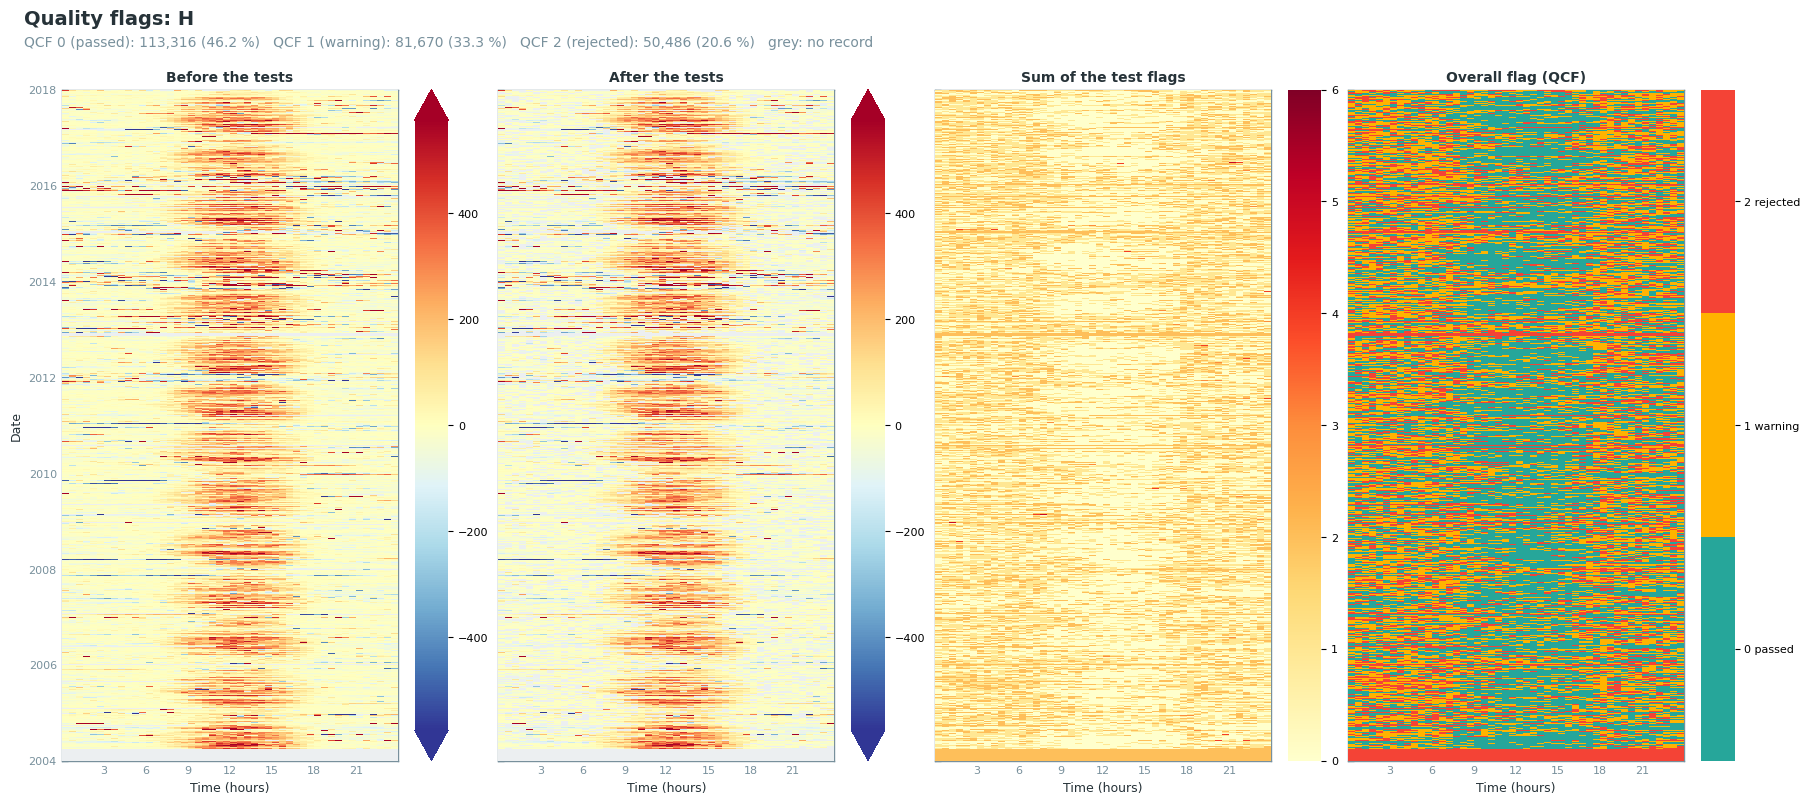

In [8]:
data.levels.level2_qcf.showplot_qcf_heatmaps()

### 📋 Table: result of each Level-2 test

In [9]:
data.levels.level2_qcf.report_qcf_flags()

Test flags: H
Measured records: 233,830 of 245,472
Missing records: 11,642 (4.74 %), flagged by the missing-values test
                                                             Pass     Warn     Fail    Fail      Not
Test                                   Period    Tested       (0)      (1)      (2)       %   tested
────────────────────────────────────────────────────────────────────────────────────────────────────
L2_H_SSITC                             all      233,830   113,769   81,968   38,093   16.29        0
                                       day      117,025    67,612   34,301   15,112   12.91        0
                                       night    116,805    46,157   47,667   22,981   19.67        0
                                                                                                    
L2_H_SCF                               all      233,830   233,828        2        0    0.00        0
                                       day      117,025   117,024        1        0    0.00        0
                                       night    116,805   116,804        1        0    0.00        0
                                                                                                    
L2_H_T_SONIC_VM97_SPIKE_HF             all      233,830   233,074        0      756    0.32        0
                                       day      117,025   116,659        0      366    0.31        0
                                       night    116,805   116,415        0      390    0.33        0
                                                                                                    
L2_H_T_SONIC_VM97_DROPOUT_HF           all      233,830   233,830        0        0    0.00        0
                                       day      117,025   117,025        0        0    0.00        0
                                       night    116,805   116,805        0        0    0.00        0
                                                                                                    
L2_H_T_SONIC_VM97_ABSOLUTE_LIMITS_HF   all      233,830   233,672        0      158    0.07        0
                                       day      117,025   116,941        0       84    0.07        0
                                       night    116,805   116,731        0       74    0.06        0

## Step 3: no storage term (Level 3.1)

`H` has no storage term, as in FLUXNET2015 and ONEFlux (Pastorello et al. 2020). Levels 3.2 and
3.3 need Level 3.1, so `run_level31` runs with `set_storage_to_zero=True`: the column `H_L3.1`
equals `H` ([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#storage-term)).

In [10]:
data = run_level31(data, set_storage_to_zero=True, gapfill_storage_term=False)
print(f'After L3.1: {data.filteredseries.dropna().count():,} valid records '
      f'(col: {data.filteredseries.name})')

────────────────────────────────── Level 3.1: Storage Correction ───────────────────────────────────

> Calculating storage-corrected flux H_L3.1 from flux H + storage term set to zero

After L3.1: 194,986 valid records (col: H_L3.1_QCF)


## Step 4: outlier removal (Level 3.2)

Four tests. Check each plot, then accept the test with `sod.addflag()` in the cell below it.

1. Periods in `REMOVE_DATES`, removed by hand; the reason for each is given in *Settings*.
2. Absolute limits `ABSLIM`.
3. Hampel filter on double differences: single spikes.
4. Hampel filter per time of day: values wrong for their time of day.

Negative nighttime values are not tested: a negative `H` at night is physical. How the tests work:
[diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#outlier-tests). The table at the end of this step lists further tests.

In [11]:
data, sod = make_level32_detector(data)

### 📊 Plot: periods removed by hand

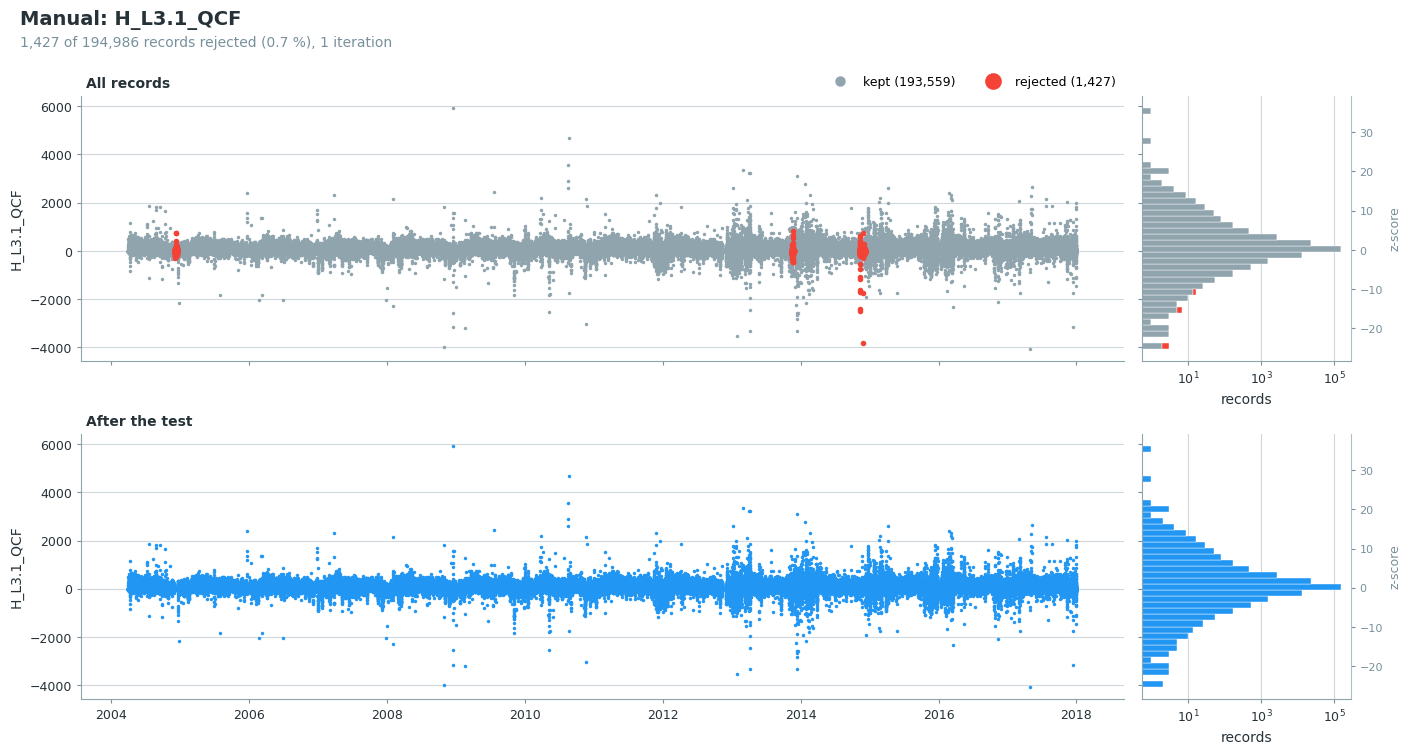

In [12]:
# Only the date ranges that overlap the processed records; none means no test and no flag.
_first, _last = data.full_df.index[0], data.full_df.index[-1]
_remove = [_d for _d in REMOVE_DATES
           if pd.Timestamp(_d[0]) <= _last and pd.Timestamp(_d[1]) + pd.Timedelta('1D') > _first]
if _remove:
    sod.flag_manualremoval_test(remove_dates=_remove, showplot=True, verbose=True)
else:
    print(f"No manual removal dates in {_first:%Y-%m-%d} - {_last:%Y-%m-%d}; test skipped.")

In [13]:
if _remove:
    sod.addflag()  # accept the manual removal

> ++Added flag column FLAG_L3.2_H_L3.1_QCF_OUTLIER_MANUAL_TEST to flag data

### 📊 Plot: absolute limits

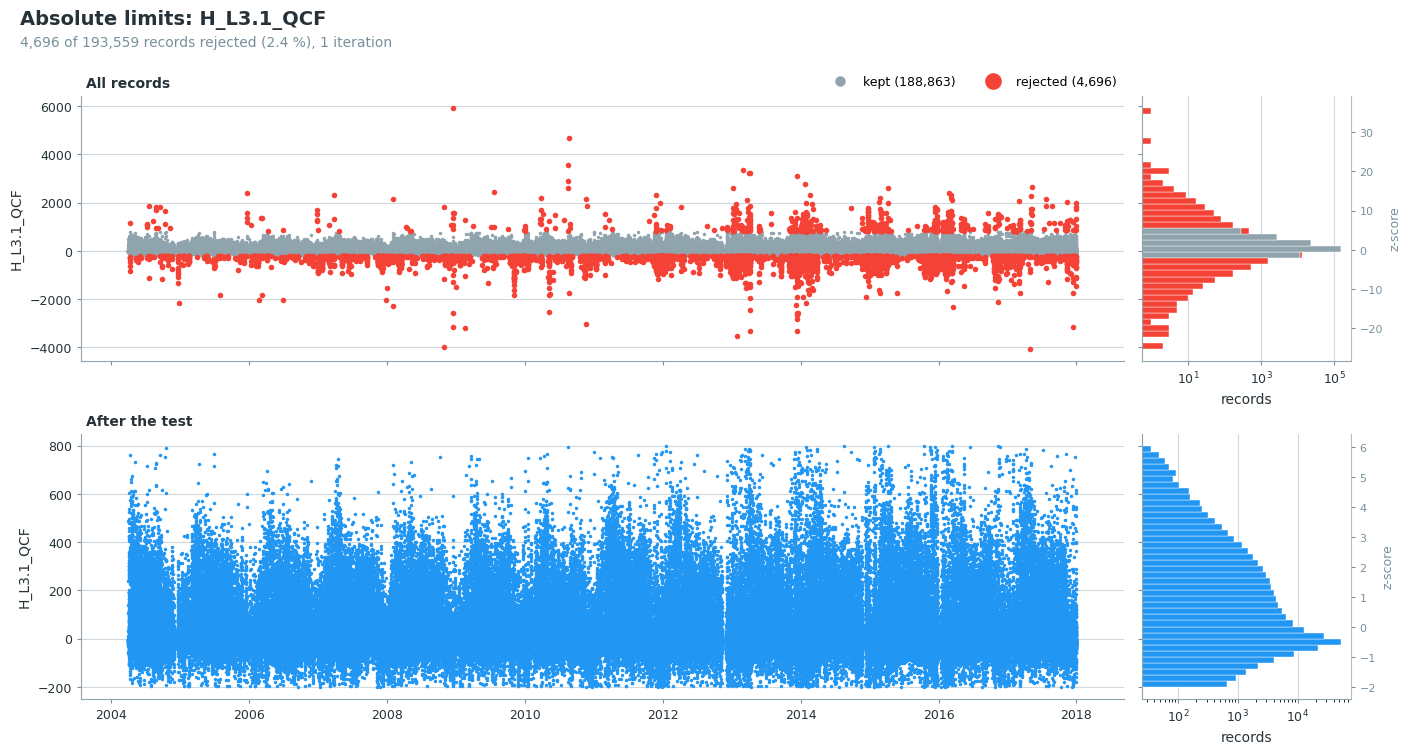

In [14]:
sod.flag_outliers_abslim_test(minval=ABSLIM[0], maxval=ABSLIM[1], showplot=True, verbose=True)

In [15]:
sod.addflag()  # accept this test

> ++Added flag column FLAG_L3.2_H_L3.1_QCF_OUTLIER_ABSLIM_TEST to flag data

### 📊 Plot: Hampel filter on double differences

[Dt/Nt] ITER #01 | Outliers:  4853 (  2.57%) | Day:  1395 | Night:  3458

[Dt/Nt] ITER #02 | Outliers:   816 (  0.44%) | Day:   199 | Night:   617

[Dt/Nt] ITER #03 | Outliers:   187 (  0.10%) | Day:    28 | Night:   159

[Dt/Nt] ITER #04 | Outliers:    40 (  0.02%) | Day:    15 | Night:    25

[Dt/Nt] ITER #05 | Outliers:     6 (  0.00%) | Day:     1 | Night:     5

[Dt/Nt] ITER #06 | Outliers:     1 (  0.00%) | Day:     0 | Night:     1

[Dt/Nt] ITER #07 | Outliers:     0 (  0.00%) | Day:     0 | Night:     0

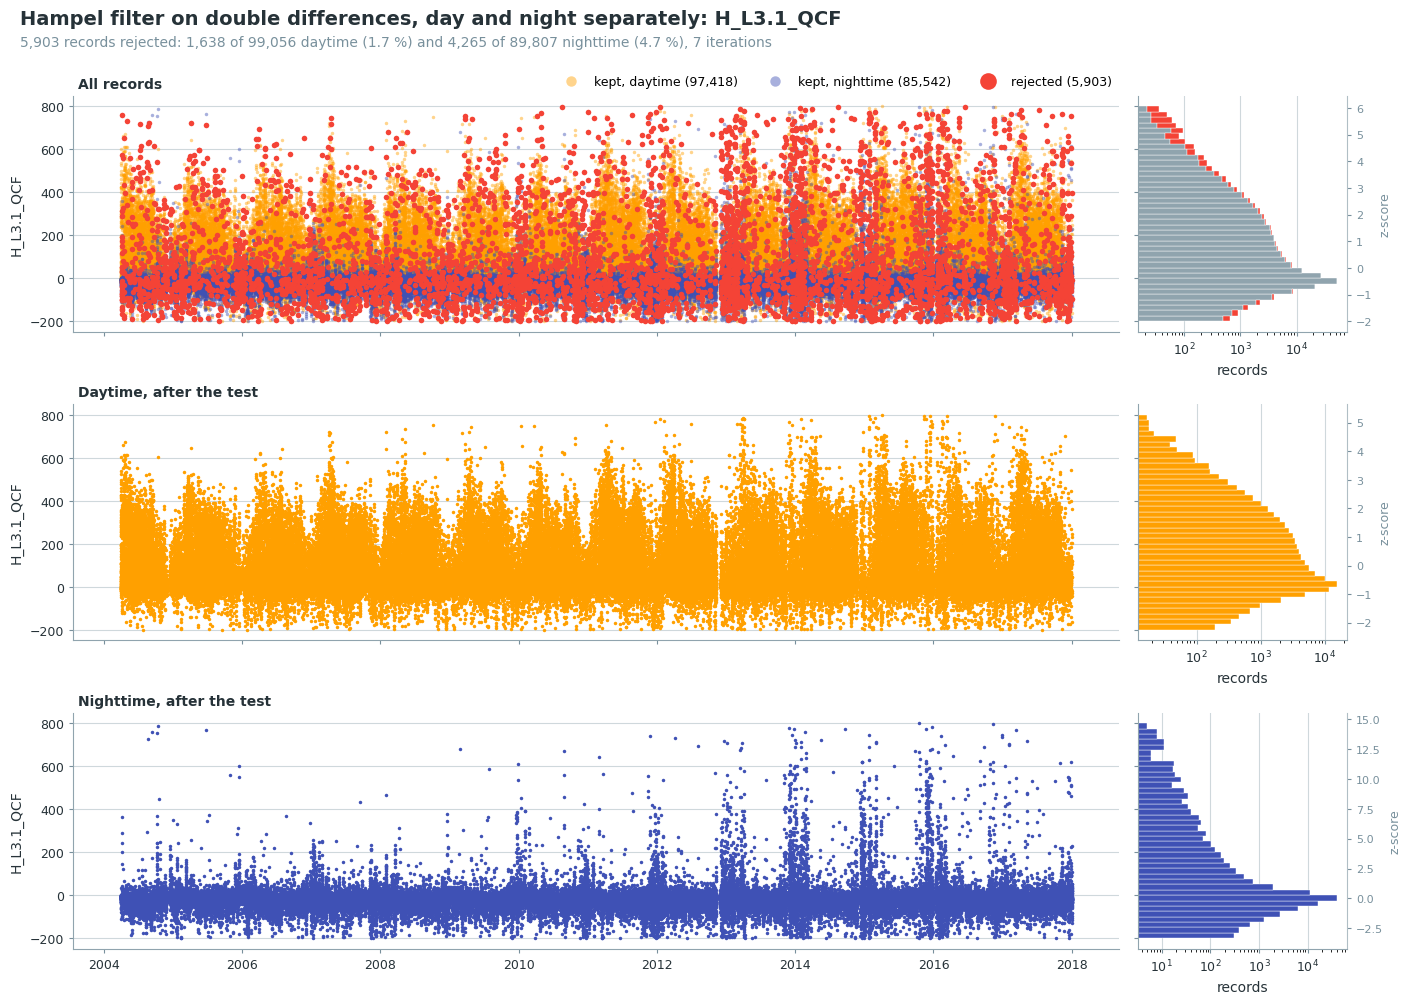

In [16]:
sod.flag_outliers_hampel_test(window_length=48 * 13, n_sigma=5.5, use_differencing=True,
                              separate_day_night=True, showplot=True, verbose=True, repeat=True)

In [17]:
sod.addflag()  # accept this test

> ++Added flag column FLAG_L3.2_H_L3.1_QCF_OUTLIER_HAMPEL_TEST to flag data

### 📊 Plot: Hampel filter on values per time of day

[Dt/Nt] ITER #01 | Outliers:  3650 (  1.99%) | Day:   965 | Night:  2685

[Dt/Nt] ITER #02 | Outliers:   652 (  0.36%) | Day:   164 | Night:   488

[Dt/Nt] ITER #03 | Outliers:   186 (  0.10%) | Day:    46 | Night:   140

[Dt/Nt] ITER #04 | Outliers:    54 (  0.03%) | Day:    14 | Night:    40

[Dt/Nt] ITER #05 | Outliers:    19 (  0.01%) | Day:     4 | Night:    15

[Dt/Nt] ITER #06 | Outliers:     8 (  0.00%) | Day:     3 | Night:     5

[Dt/Nt] ITER #07 | Outliers:     6 (  0.00%) | Day:     1 | Night:     5

[Dt/Nt] ITER #08 | Outliers:     2 (  0.00%) | Day:     0 | Night:     2

[Dt/Nt] ITER #09 | Outliers:     0 (  0.00%) | Day:     0 | Night:     0

! Hampel: 33 record(s) were not tested because their time-of-day window held fewer than 
min_records=10 values. They keep flag 0. Consider a longer window_length or more time_of_day_slots.

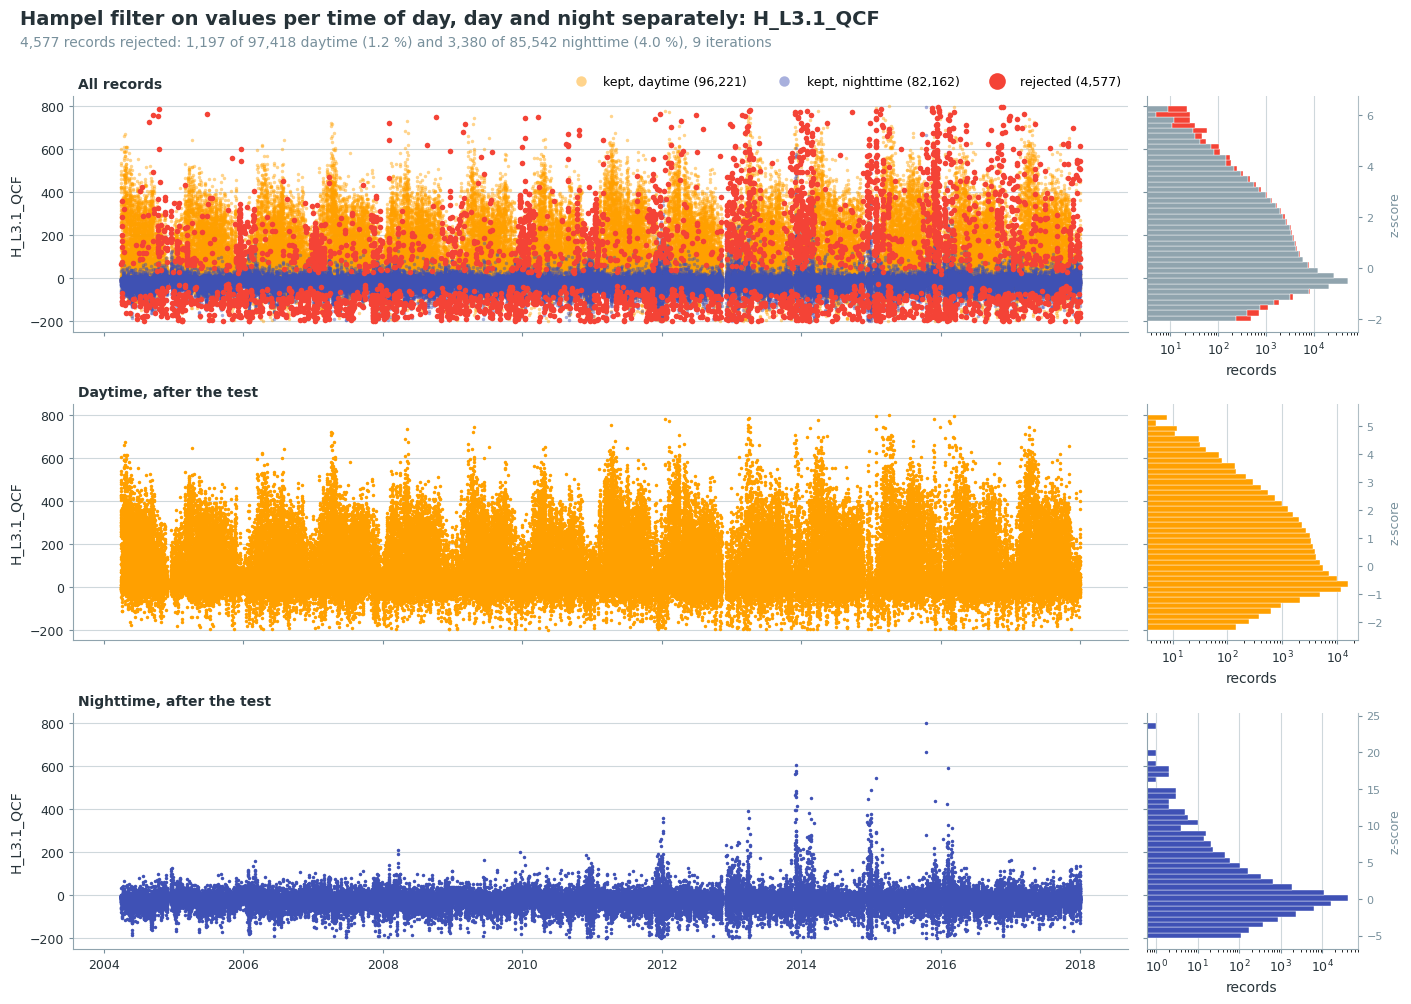

In [18]:
sod.flag_outliers_hampel_test(window_length=48 * 13, n_sigma=5.5, use_differencing=False,
                              by_time_of_day=True, time_of_day_slots=1, min_records=10,
                              separate_day_night=True, showplot=True, verbose=True, repeat=True)

In [19]:
sod.addflag()  # accept this test

> ++Added flag column FLAG_L3.2_H_L3.1_QCF_OUTLIER_HAMPEL_2_TEST to flag data

### 📋 Table: outlier tests available in diive

Every test of the outlier detector `sod`, with the ones used above marked. `help(sod.<method>)`
shows the settings of a test.

In [20]:
_used = {'flag_manualremoval_test', 'flag_outliers_abslim_test', 'flag_outliers_hampel_test'}
_rows = []
for _name in sorted(dir(type(sod))):
    if not (_name.startswith('flag_') and _name.endswith('_test')):
        continue
    # The first sentence of the docstring, which may run over two lines.
    _doc = (getattr(type(sod), _name).__doc__ or '').strip().split('\n\n')[0]
    _first = ' '.join(_doc.split()).split('. ')[0].rstrip('.')
    _rows.append({'method': f'sod.{_name}()', 'what it does': _first,
                  'used here': 'yes' if _name in _used else ''})
display(pd.DataFrame(_rows).set_index('method'))

,what it does,used here
method,,
sod.flag_manualremoval_test(),Flag specified records for removal,yes
sod.flag_missingvals_test(),Flag missing records in the data (flag 2 where...,
sod.flag_outliers_abslim_test(),Identify outliers based on absolute limits,yes
sod.flag_outliers_hampel_test(),Identify outliers in a sliding window based on...,yes
sod.flag_outliers_increments_zcore_test(),Identify outliers based on the z-score of reco...,
sod.flag_outliers_localsd_test(),Identify outliers based on standard deviation ...,
sod.flag_outliers_lof_test(),Local outlier factor detection (global or sepa...,
sod.flag_outliers_negative_night_test(),Flag nighttime values below -z times their ran...,
sod.flag_outliers_negative_nights_test(),Flag all records of nights whose median lies b...,


### Apply the Level-3.2 flags

In [21]:
data = run_level32(data, outlier_detector=sod)
print(f'After L3.2: {data.filteredseries.dropna().count():,} valid records')

────────────────────────────── Level 3.2: Stepwise Outlier Detection ───────────────────────────────

After L3.2: 178,383 valid records


### 📊 Plot: all removed outliers

Every record Level 3.2 removed, coloured by the test that removed it, with the share removed per
month and per hour of the day.

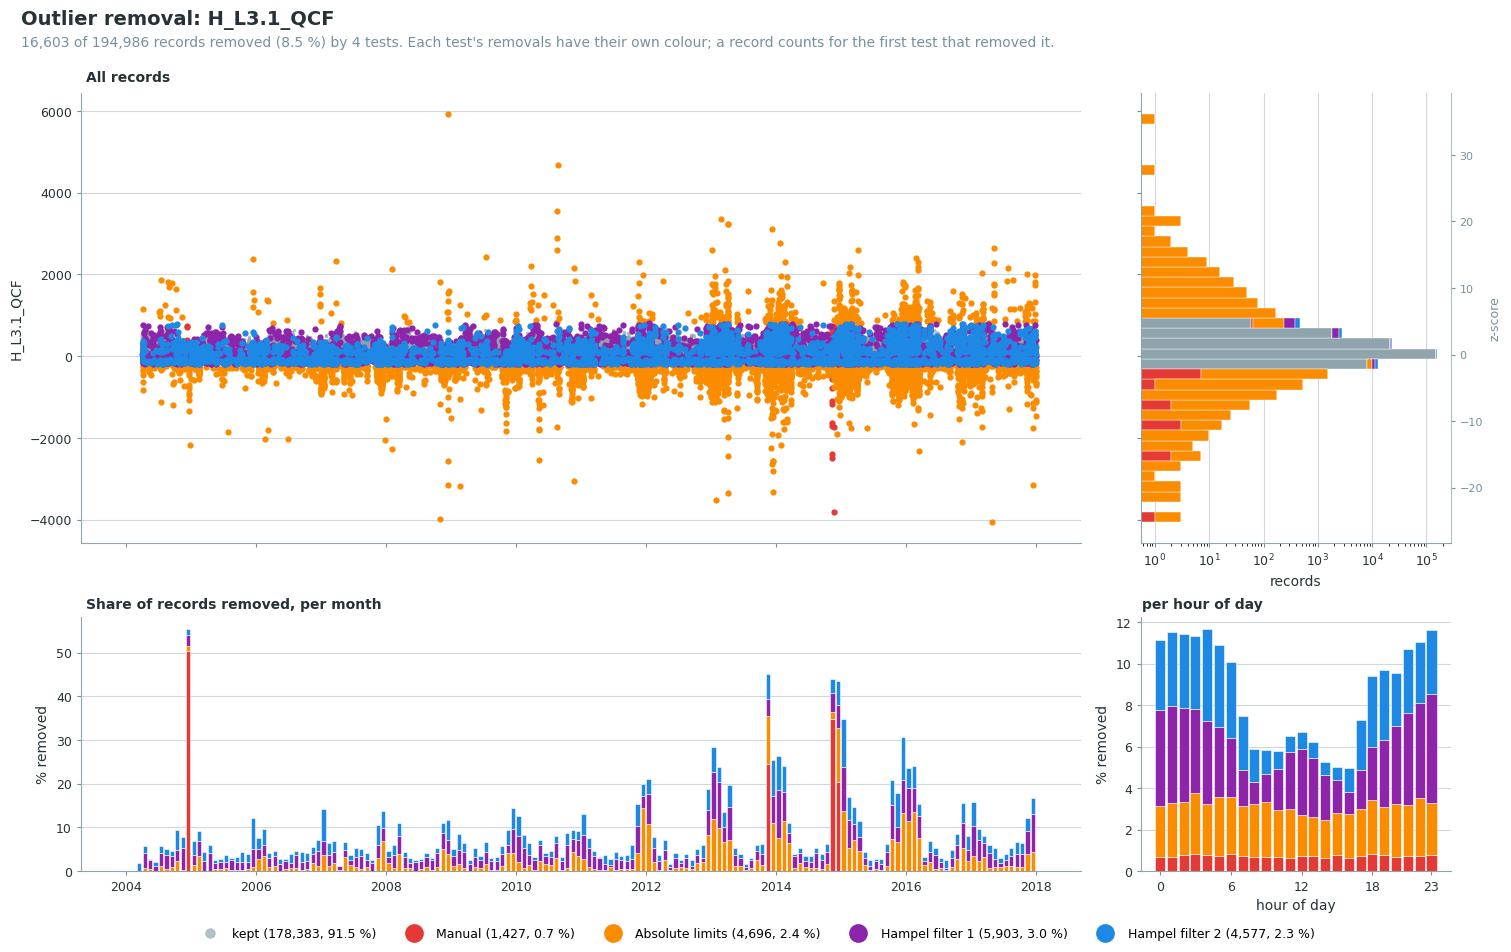

In [22]:
data.levels.level32.showplot_overview();

### 📊 Plot: Level-3.2 quality flag over time

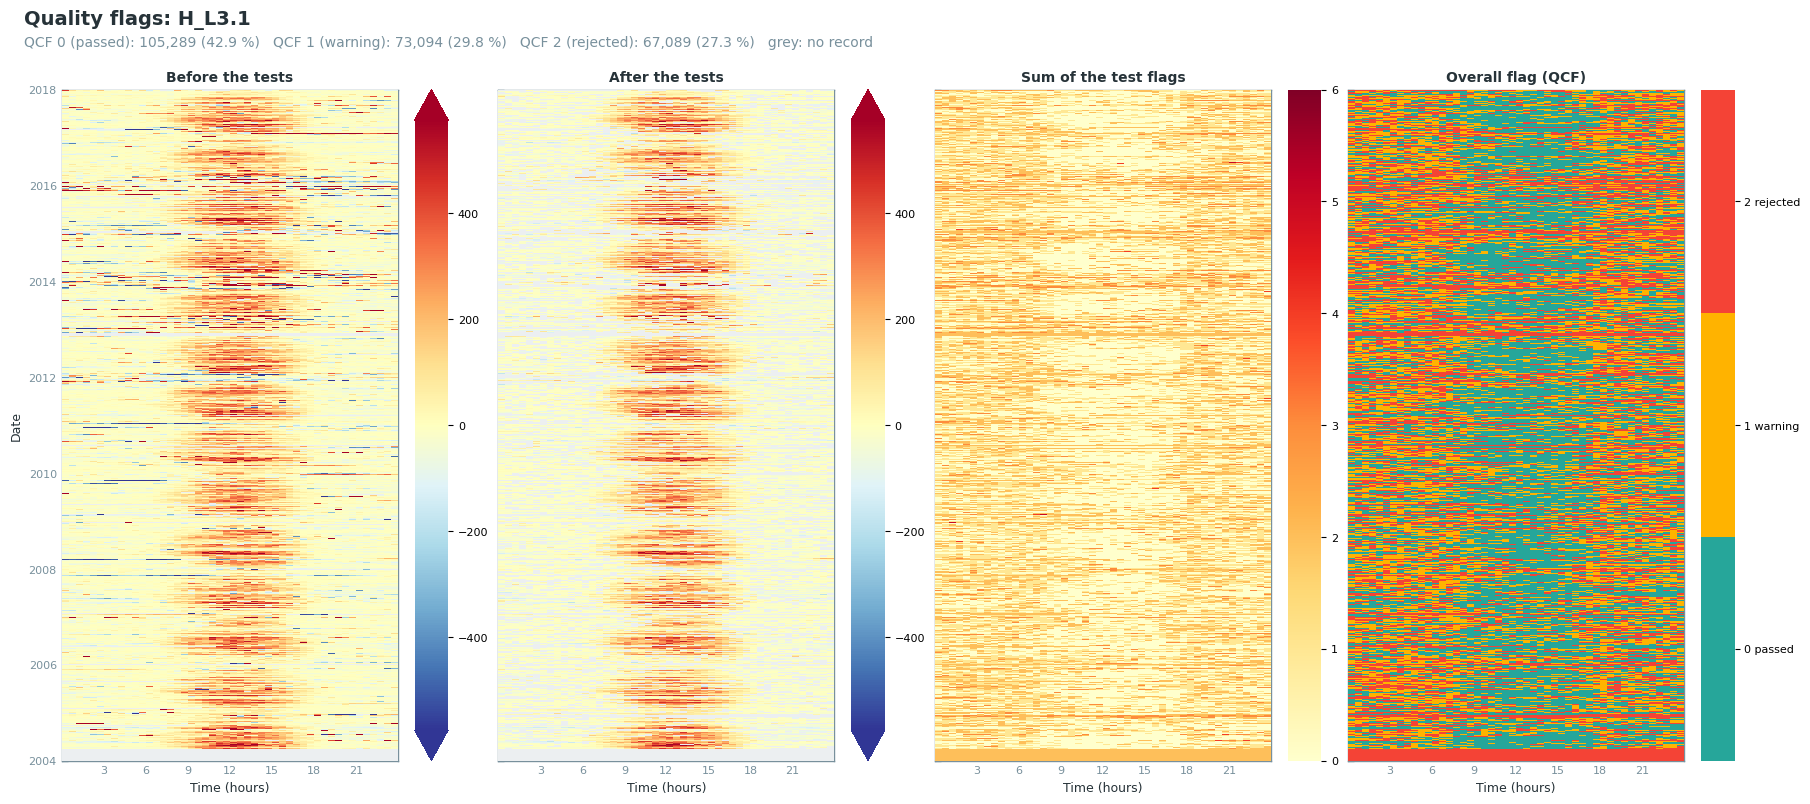

In [23]:
data.levels.level32_qcf.showplot_qcf_heatmaps()

### 📋 Table: result of each Level-3.2 test

In [24]:
data.levels.level32_qcf.report_qcf_flags()

Test flags: H_L3.1
Measured records: 233,830 of 245,472
Missing records: 11,642 (4.74 %), flagged by the missing-values test
                                                             Pass     Warn     Fail    Fail      Not
Test                                   Period    Tested       (0)      (1)      (2)       %   tested
────────────────────────────────────────────────────────────────────────────────────────────────────
L2_H_SSITC                             all      233,830   113,769   81,968   38,093   16.29        0
                                       day      117,025    67,612   34,301   15,112   12.91        0
                                       night    116,805    46,157   47,667   22,981   19.67        0
                                                                                                    
L2_H_SCF                               all      233,830   233,828        2        0    0.00        0
                                       day      117,025   117,024        1        0    0.00        0
                                       night    116,805   116,804        1        0    0.00        0
                                                                                                    
L2_H_T_SONIC_VM97_SPIKE_HF             all      233,830   233,074        0      756    0.32        0
                                       day      117,025   116,659        0      366    0.31        0
                                       night    116,805   116,415        0      390    0.33        0
                                                                                                    
L2_H_T_SONIC_VM97_DROPOUT_HF           all      233,830   233,830        0        0    0.00        0
                                       day      117,025   117,025        0        0    0.00        0
                                       night    116,805   116,805        0        0    0.00        0
                                                                                                    
L2_H_T_SONIC_VM97_ABSOLUTE_LIMITS_HF   all      233,830   233,672        0      158    0.07        0
                                       day      117,025   116,941        0       84    0.07        0
                                       night    116,805   116,731        0       74    0.06        0
                                                                                                    
L3.2_H_L3.1_QCF_OUTLIER_MANUAL         all      194,986   193,559        0    1,427    0.73   38,844
                                       day      101,535   101,010        0      525    0.52   15,490
                                       night     93,451    92,549        0      902    0.97   23,354
                                                                                                    
L3.2_H_L3.1_QCF_OUTLIER_ABSLIM         all      193,559   188,863        0    4,696    2.43   40,271
                                       day      101,010    99,056        0    1,954    1.93   16,015
                                       night     92,549    89,807        0    2,742    2.96   24,256
                                                                                                    
L3.2_H_L3.1_QCF_OUTLIER_HAMPEL         all      188,863   182,960        0    5,903    3.13   44,967
                                       day       99,056    97,418        0    1,638    1.65   17,969
                                       night     89,807    85,542        0    4,265    4.75   26,998
                                                                                                    
L3.2_H_L3.1_QCF_OUTLIER_HAMPEL_2       all      182,960   178,383        0    4,577    2.50   50,870
                                       day       97,418    96,221        0    1,197    1.23   19,607
                                       night     85,542    82,162        0    3,380    3.95   31,263

## Step 5: no USTAR filter (Level 3.3)

No USTAR filter for `H`, as in FLUXNET2015 and ONEFlux (Pastorello et al. 2020). Level 4.1 reads
Level 3.3, so the chain runs one scenario, `CUT_NONE`, with threshold 0, which removes no record.
Column names carry `_L3.3_CUT_NONE_` ([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#ustar-filter)).

In [25]:
data = run_level33_constant_ustar(
    data,
    thresholds=USTAR_THRESHOLDS,
    threshold_labels=USTAR_SCENARIOS,
    showplot=False,
    verbose=True,
)

──────────────────────────────────── Level 3.3: USTAR Filtering ────────────────────────────────────

> QCF computed for USTAR scenario CUT_NONE

### Records for gap-filling and highest-quality records

The records the gap-filling starts from (QCF 0 and 1, columns `_QCF`) and the highest-quality
records (QCF 0, columns `_QCF0`) for analyses without gap-filled values
([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#gapfilling-input)).

### 📋 Table: records for gap-filling

In [26]:
report_gapfilling_input(data);

Records for gap-filling
                      removed:   removed:               used:    used:    used:    used:
USTAR      measured      tests      USTAR      used     QCF 0    QCF 1      day    night
────────────────────────────────────────────────────────────────────────────────────────
CUT_NONE    233,830     55,447          0   178,383   105,289   73,094   96,221   82,162
                95%        23%         0%       73%       43%      30%      39%      33%
Records, and their share of all 245,472 records of the period.
removed: tests = quality tests and outlier detection (Levels 2 to 3.2).
used = records for gap-filling: QCF below 2 by day and below 2 by night. QCF 0 is the highest 
quality, the measured flux for analyses without gap-filled values.

### 📊 Plot: records for gap-filling and highest-quality records

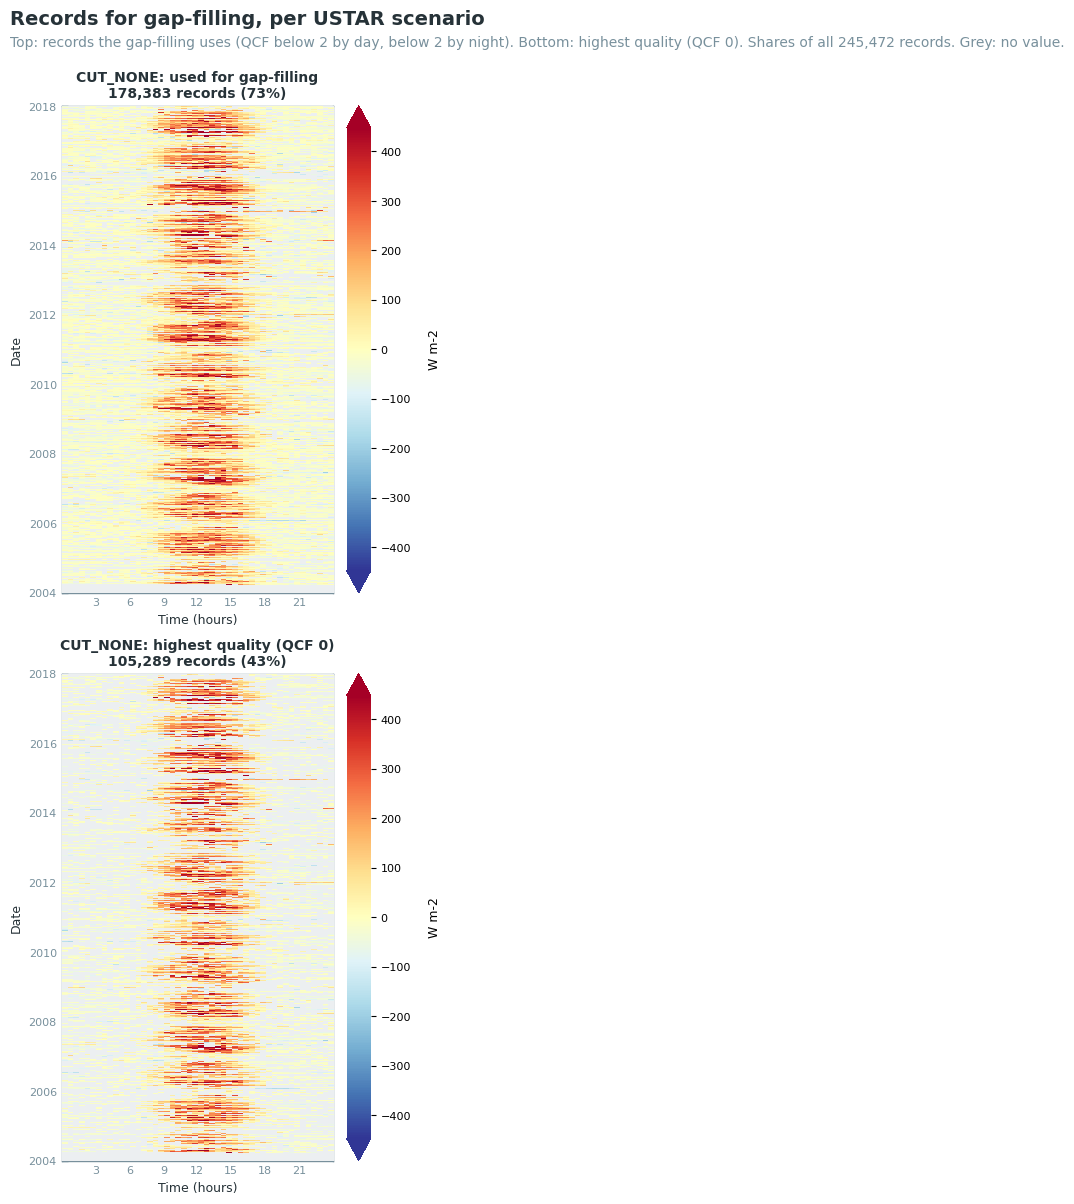

In [27]:
plot_gapfilling_input(data, units=FLUX_UNITS)

### 📋 Table: gaps to fill

The gaps left after Level 3.3, which the gap-filling has to fill. A long gap lasts at least one day.

In [28]:
report_gaps(data, long_gap_days=1);

Gaps to fill
USTAR      missing %    gaps   long gaps   longest gap (days)   worst month   worst month missing %
───────────────────────────────────────────────────────────────────────────────────────────────────
CUT_NONE        27.3   30418          36                 89.6           Jan                    41.1
A long gap lasts at least 1 day.

## Step 6: model features

The feature engineer adds lagged values, rolling statistics and time terms to the drivers. It is built once and passed to XGBoost. `target_col` is only a placeholder.

In [29]:
engineer = FeatureEngineer(
    target_col='_target_',
    features_lag=[-2, 2],
    features_lag_stepsize=1,
    features_rolling=[2, 4, 12, 24, 48],
    features_rolling_stats=['median', 'min', 'max', 'std'],
    features_ema=[6, 12, 24, 48],
    vectorize_timestamps=True,
    add_continuous_record_number=True,
    sanitize_timestamp=True,
    verbose=0,
)

## Step 7: gap-filling (Level 4.1)

XGBoost and MDS fill the gaps; MDS is the method of FLUXNET2015 and ONEFlux for the energy fluxes
(Pastorello et al. 2020). Step 10 compares the two.

### XGBoost

One model per year, trained on three years, with features selected by SHAP
([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#xgboost-gapfilling)).

The number of trees is chosen once for all models by blocked cross-validation
([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#tree-selection)).

In [30]:
data = run_level41_xgb(
    data,
    features=FEATURES,
    engineer=engineer,
    reduce_features=True,
    n_estimators_cv=True,
    verbose=1,
    **XGB_SETTINGS,
)

───────────────────────────────── Level 4.1: Gap-Filling (XGBoost) ─────────────────────────────────

### MDS

Marginal distribution sampling (Reichstein et al. 2005) in `mode='diive'`, filling every gap from
measured driver values only ([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#mds-gapfilling)).

**Skipped** when `RUN_MDS = False`.

In [31]:
if RUN_MDS:
    data = run_level41_mds(
        data,
        swin=SW_IN_F, ta=TA_F, vpd=VPD_F,  # W m-2, degC, kPa
        swin_qc=SW_IN_FLAG, ta_qc=TA_FLAG, vpd_qc=VPD_FLAG,
        **MDS_SETTINGS,
    )

─────────────────────────────────── Level 4.1: Gap-Filling (MDS) ───────────────────────────────────

## Step 8: results

How many records were measured and how many were filled, then the annual sum of the flux. The
share measured is given in brackets: a year with long gaps rests largely on the model. An incomplete
year is marked.

### 📋 Table: measured and filled records

In [32]:
report_gapfilling_variables(data)

Gap-filled variables
method    USTAR      records   measured   filled   filled %
───────────────────────────────────────────────────────────
MDS       CUT_NONE   245,472    178,383   67,089       27.3
XGBoost   CUT_NONE   245,472    178,383   67,089       27.3
MDS (CUT_NONE): H_L3.1_L3.3_CUT_NONE_QCF -> H_L3.1_L3.3_CUT_NONE_QCF_gfMDS
XGBoost (CUT_NONE): H_L3.1_L3.3_CUT_NONE_QCF -> H_L3.1_L3.3_CUT_NONE_QCF_gfXG

### 📋 Table: annual sums of the flux

In [33]:
report_annual_sums(data, gain=WM2_TO_MJ, units='MJ m-2');

Annual sums (MJ m-2)
               MDS       XGBoost
year      CUT_NONE      CUT_NONE
────────────────────────────────
2004   1,634 (56%)   1,106 (56%)
2005   1,013 (78%)     994 (78%)
2006     919 (78%)     927 (78%)
2007   1,014 (78%)   1,013 (78%)
2008     937 (78%)     936 (78%)
2009     958 (76%)     958 (76%)
2010     916 (74%)     915 (74%)
2011   1,208 (76%)   1,201 (76%)
2012   1,013 (71%)   1,033 (71%)
2013   1,163 (69%)   1,171 (69%)
2014   1,143 (69%)   1,144 (69%)
2015   1,439 (68%)   1,458 (68%)
2016   1,064 (72%)   1,103 (72%)
2017   1,291 (75%)   1,303 (75%)
In brackets: the share of the year's records that were measured.

## Step 9: model quality

First the scores on test data: a random 25 % of the complete records, which the model did not see in
training. The number of trees is chosen without the test data. Because the test
records lie between training records, the scores describe short gaps better than gaps of several
days.

### 📋 Table: scores on test data

In [34]:
report_traintest_model_scores(data)

Held-out test scores
method    USTAR      year      R²    RMSE     MAE   MedAE    MaxE
─────────────────────────────────────────────────────────────────
XGBoost   CUT_NONE   2004   0.846   40.49   26.50   15.87   292.5
XGBoost   CUT_NONE   2005   0.846   40.49   26.50   15.87   292.5
XGBoost   CUT_NONE   2006   0.831   42.43   27.45   16.36   521.7
XGBoost   CUT_NONE   2007   0.827   43.49   28.05   16.64   537.5
XGBoost   CUT_NONE   2008   0.831   43.75   28.06   16.81   496.7
XGBoost   CUT_NONE   2009   0.827   43.71   28.29   16.99   459.7
XGBoost   CUT_NONE   2010   0.831   46.38   29.61   17.33   457.4
XGBoost   CUT_NONE   2011   0.827   48.63   31.41   18.53   460.2
XGBoost   CUT_NONE   2012   0.786   56.54   34.45   19.51   596.0
XGBoost   CUT_NONE   2013   0.760   59.83   35.71   19.61   731.5
XGBoost   CUT_NONE   2014   0.755   63.23   37.27   20.28   728.7
XGBoost   CUT_NONE   2015   0.776   59.77   35.63   20.14   728.9
XGBoost   CUT_NONE   2016   0.790   57.16   34.01   19.08   680.7
XGBoost   CUT_NONE   2017   0.790   57.16   34.01   19.08   680.7
XGBoost   CUT_NONE   mean   0.809   50.22   31.21   18.01   547.5
Test set: a random share of the complete records, not used in training.
Errors are in the units of the flux.
Not available for MDS (CUT_NONE).

### 📋 Table: gap-filling models per year

How each model was built and how well it did: the years it was trained on, its features, the
training and test records, the number of trees, the records of the final fit,
the test scores, and how the gaps of its year were filled.

In [35]:
report_model_overview(data);

Gap-filling models
                  trained                                           final    test    test            fall-
USTAR      year   on          features    train     test   trees      fit      R²    RMSE   filled    back
──────────────────────────────────────────────────────────────────────────────────────────────────────────
CUT_NONE   2004   2004-2006         94   28,040    9,182     100   37,222   0.846   40.49    7,737       0
CUT_NONE   2005   2004-2006         94   28,040    9,182     100   37,222   0.846   40.49    3,827       0
CUT_NONE   2006   2005-2007         94   30,953   10,085     100   41,038   0.831   42.43    3,822       0
CUT_NONE   2007   2006-2008         94   31,003   10,072     100   41,075   0.827   43.49    3,873       0
CUT_NONE   2008   2007-2009         94   30,636   10,053     100   40,689   0.831   43.75    3,838       0
CUT_NONE   2009   2008-2010         94   29,980    9,951     100   39,931   0.827   43.71    4,208       0
CUT_NONE   2010   2009-2011         94   29,624    9,968     100   39,592   0.831   46.38    4,631       0
CUT_NONE   2011   2010-2012         94   28,966    9,710     100   38,676   0.827   48.63    4,129       0
CUT_NONE   2012   2011-2013         94   28,358    9,438     100   37,796   0.786   56.54    5,172       0
CUT_NONE   2013   2012-2014         94   27,338    9,203     100   36,541   0.760   59.83    5,511       0
CUT_NONE   2014   2013-2015         94   27,005    9,048     100   36,053   0.755   63.23    5,384       0
CUT_NONE   2015   2014-2016         94   27,521    9,129     100   36,650   0.776   59.77    5,612       0
CUT_NONE   2016   2015-2017         94   28,274    9,377     100   37,651   0.790   57.16    4,962       0
CUT_NONE   2017   2015-2017         94   28,274    9,377     100   37,651   0.790   57.16    4,383       0
Each year has its own model, trained on that year and its neighbours ('trained on').
train / test: a random 75 / 25 % split of the complete records; the test scores come from the 25 %, which 
the model did not see.
trees: 100 for every model, chosen by blocked cross-validation (report_tree_selection).
final fit: the gaps are filled by a model refitted on all complete records with that number of trees. 
filled / fallback: gaps of the model year filled by this model, or by the fallback model on timestamp 
features where a driver was missing.
XGBoost: learning_rate=0.05, max_depth=6, n_estimators=100, n_jobs=-1, random_state=42

### 📋 Table: number of trees from blocked cross-validation

The scores on held-out blocks of days at the chosen number of trees, next to the scores on the
random test records. The blocked scores describe gaps of days, the random ones single missing
records ([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#tree-selection)).

In [36]:
report_tree_selection(data);

Number of trees from blocked cross-validation
                      blocked   blocked   blocked   random   random
pool        records      RMSE       MAE        R²     RMSE       R²
───────────────────────────────────────────────────────────────────
2004-2006    28,040     45.76     29.12     0.810    40.49    0.846
2005-2007    30,953     45.94     29.52     0.804    42.43    0.831
2006-2008    31,003     46.91     30.43     0.804    43.49    0.827
2007-2009    30,636     45.95     29.70     0.816    43.75    0.831
2008-2010    29,980     45.93     29.74     0.806    43.71    0.827
2009-2011    29,624     48.28     31.21     0.809    46.38    0.831
2010-2012    28,966     51.37     33.27     0.797    48.63    0.827
2011-2013    28,358     59.63     36.78     0.751    56.54    0.786
2012-2014    27,338     61.48     37.83     0.733    59.83    0.760
2013-2015    27,005     66.35     39.57     0.722    63.23    0.755
2014-2016    27,521     63.32     37.88     0.743    59.77    0.776
2015-2017    28,274     61.43     36.48     0.760    57.16    0.790
100 trees for every model: the minimum of the median error curve of the pools, rounded to ten (up to
1000 tested). USTAR scenario CUT_NONE.
blocked: 5-fold cross-validation on the training records of each pool, holding out whole 14-day 
blocks, at the chosen number of trees. R² from the RMSE and the variance of the target.
random: the test records of the models of that pool, random single half-hours that the models did 
not see. The difference shows how much harder gaps of days are than single missing records.

### 📊 Plot: number of trees from blocked cross-validation

The error on held-out blocks against the number of trees, one line per pool, and the chosen
number. The curves should flatten well before the largest number tested.

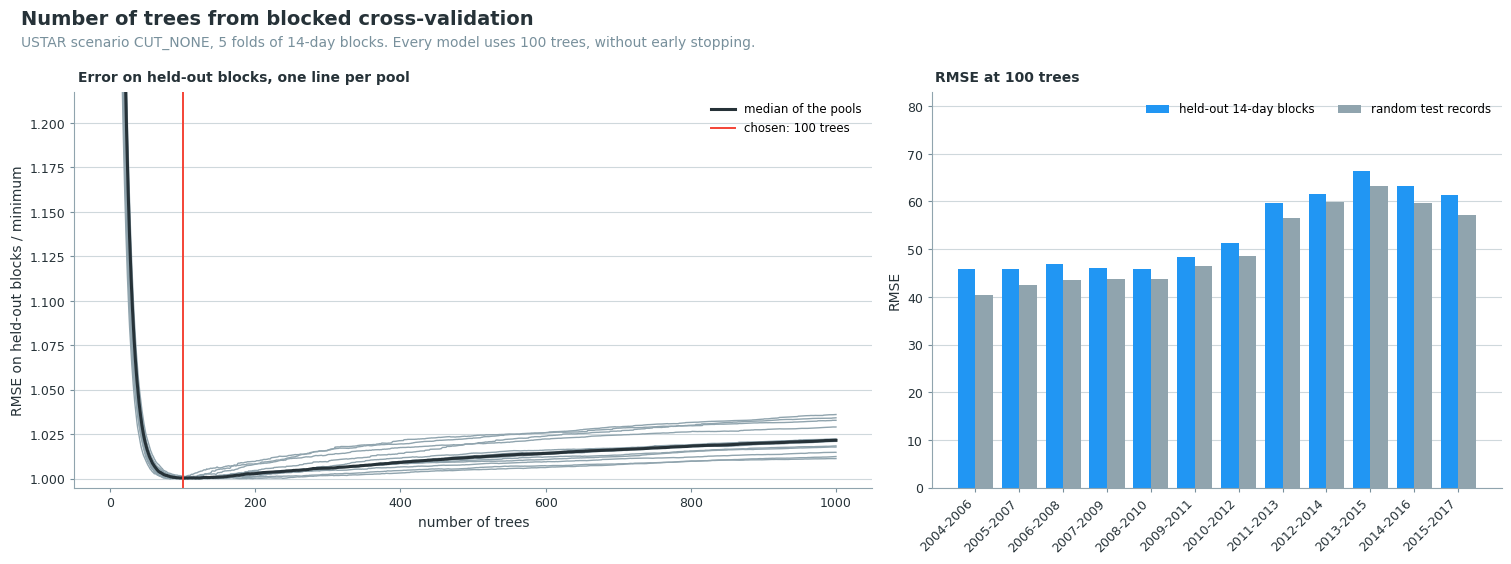

In [37]:
plot_tree_selection(data);

Next the scores on all measured records. The gaps are filled by a model refitted on all of them, so
these scores are better than the test scores and only show how closely the model fits.

### 📋 Table: scores on all measured records

In [38]:
report_gapfilling_model_scores(data)

In-sample scores
method    USTAR      year      R²    RMSE     MAE   MedAE    MaxE
─────────────────────────────────────────────────────────────────
MDS       CUT_NONE   all    0.772   54.50   33.60   18.86   797.7
XGBoost   CUT_NONE   2004   0.877   36.60   24.60   15.51   300.8
XGBoost   CUT_NONE   2005   0.877   36.60   24.60   15.51   300.8
XGBoost   CUT_NONE   2006   0.865   38.14   25.43   15.80   318.0
XGBoost   CUT_NONE   2007   0.864   38.92   26.05   16.23   317.4
XGBoost   CUT_NONE   2008   0.870   38.52   25.72   16.21   319.0
XGBoost   CUT_NONE   2009   0.864   38.58   25.70   16.12   485.3
XGBoost   CUT_NONE   2010   0.868   40.35   26.85   16.68   471.5
XGBoost   CUT_NONE   2011   0.860   42.95   28.61   17.82   460.0
XGBoost   CUT_NONE   2012   0.837   48.47   31.32   18.85   500.5
XGBoost   CUT_NONE   2013   0.821   50.74   32.10   18.94   708.8
XGBoost   CUT_NONE   2014   0.819   53.67   33.30   19.12   694.6
XGBoost   CUT_NONE   2015   0.827   52.12   32.21   18.80   806.5
XGBoost   CUT_NONE   2016   0.841   49.96   30.89   17.92   782.7
XGBoost   CUT_NONE   2017   0.841   49.96   30.89   17.92   782.7
XGBoost   CUT_NONE   mean   0.852   43.97   28.45   17.25   517.8
Model predictions against every measured record, training records included, so optimistic for the ML
methods.
MDS predicts each measured record without using it, so its scores are out-of-sample and not 
comparable with those of the ML methods; report_gapfilling_comparison scores both on the same 
held-out records.
Errors are in the units of the flux.

### 📋 Table: years used to train each year's model

In [39]:
report_gapfilling_poolyears(data)

Years pooled for each year's model
model year   trained on, all ML runs
────────────────────────────────────
2004         2004-2006              
2005         2004-2006              
2006         2005-2007              
2007         2006-2008              
2008         2007-2009              
2009         2008-2010              
2010         2009-2011              
2011         2010-2012              
2012         2011-2013              
2013         2012-2014              
2014         2013-2015              
2015         2014-2016              
2016         2015-2017              
2017         2015-2017              
Not available for MDS (CUT_NONE) (does not pool years).

### 📋 Table: most important features (SHAP)

In [40]:
report_gapfilling_feature_importances(data, ustar_scenario=SCENARIO)

Feature importances, XGBoost (CUT_NONE): top 10 of 94 features, mean |SHAP|
 #   feature                            2004    2005    2006    2007    2008    2009    2010    2011    2012    2013    2014    2015    2016    2017    mean
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
 1   .SW_IN_T1_47_1_gfXG_MEAN2         24.57   24.57   26.02   24.87   38.23   49.50   50.38   46.04   39.65   51.28   38.81   30.00   18.46   18.46   34.34
 2   SW_IN_T1_47_1_gfXG                31.56   31.56   23.68   29.57   15.97    4.00    0.45    0.64    4.32   11.42   24.51   32.62   46.93   46.93   21.73
 3   .SW_IN_T1_47_1_gfXG_ROLLMIN2       8.51    8.51    8.84    7.30   11.08    9.59    9.13   10.99   23.74    9.36   10.76   10.15    7.76    7.76   10.25
 4   .DOY_COS                           5.35    5.35    5.77    6.45    8.41    5.81    6.99    5.53    8.41    7.37    6.90    7.42    6.59    6.59    6.64
 5   .SW_IN_T1_47_1_gfXG_ROLLMAX2       1.46    1.46    2.71    2.37    3.19    1.52    2.28    4.71    4.61    3.55    1.90    5.54    6.91    6.91    3.51
 6   .HOUR_COS                          3.82    3.82    3.36    1.63    2.00    1.19    0.94    1.80    2.10    3.24    3.67    5.67    6.94    6.94    3.37
 7   .SW_IN_T1_47_1_gfXG_ROLLMEDIAN4    3.06    3.06    0.74    1.91    1.18    0.88    3.21    3.42    3.43    2.81    4.88    1.73    1.60    1.60    2.39
 8   .SW_IN_T1_47_1_gfXG_ROLLMIN4       2.58    2.58    2.60    1.63    1.54    2.24    4.08    1.72    2.87    1.18    0.67    2.18    2.43    2.43    2.20
 9   .WEEK_COS                          0.27    0.27    0.26    0.73    0.50    2.71    4.06    3.69    0.76    0.83    2.13    4.32    4.20    4.20    2.07
10   .SW_IN_T1_47_1_gfXG-1              0.25    0.25    1.42    1.36    0.71    0.98    6.81   11.70    0.88    0.59    0.41    0.75    0.55    0.55    1.94

Names starting with '.' are features engineered from the drivers (lags, rolling statistics, 
timestamp terms).
Not available for MDS (CUT_NONE) (no model trained).

### 📊 Plot: feature ranks per year

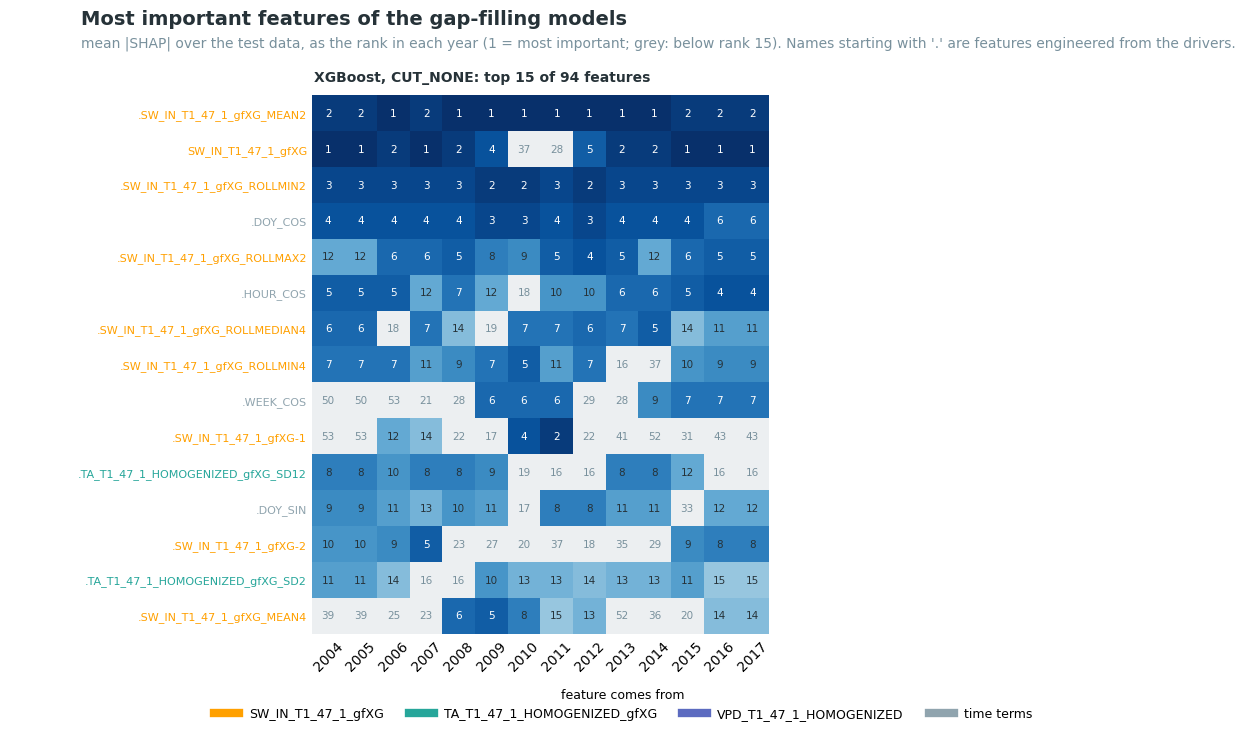

In [41]:
plot_feature_ranks_per_year(data)

## Step 10: result plots

### 📊 Plot: flux by quality class, heatmaps, XGBoost

The highest-quality records (QCF 0), the records the gap-filling used (QCF 0 and 1), the rejected
records, and the gap-filled result, on one colour scale.

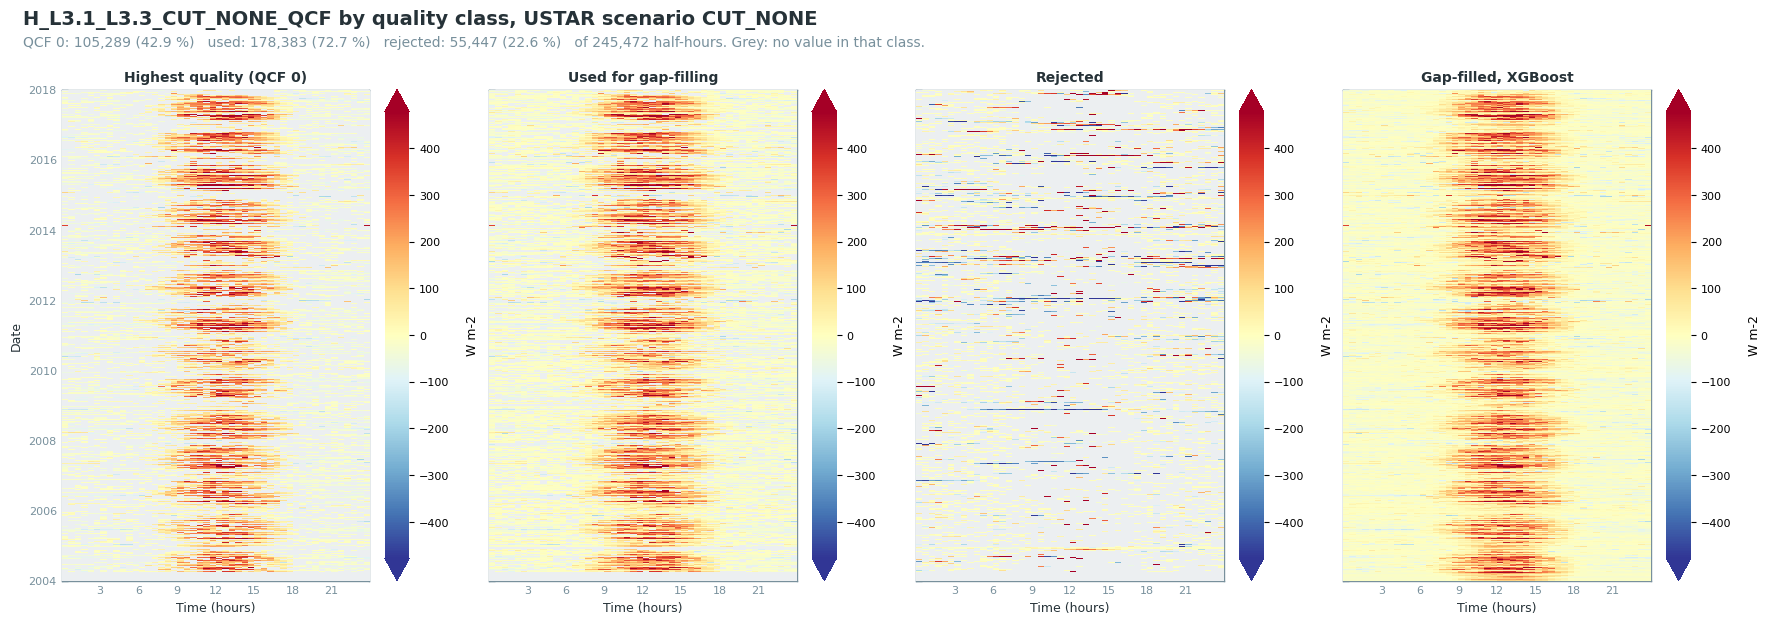

In [42]:
plot_quality_heatmaps(data, ustar_scenario=SCENARIO, units=FLUX_UNITS, method='xgb')

### 📊 Plot: flux by quality class, day and night, XGBoost

Daytime and nighttime records by quality class, then the gap-filled result, with measured and
filled records shown apart.

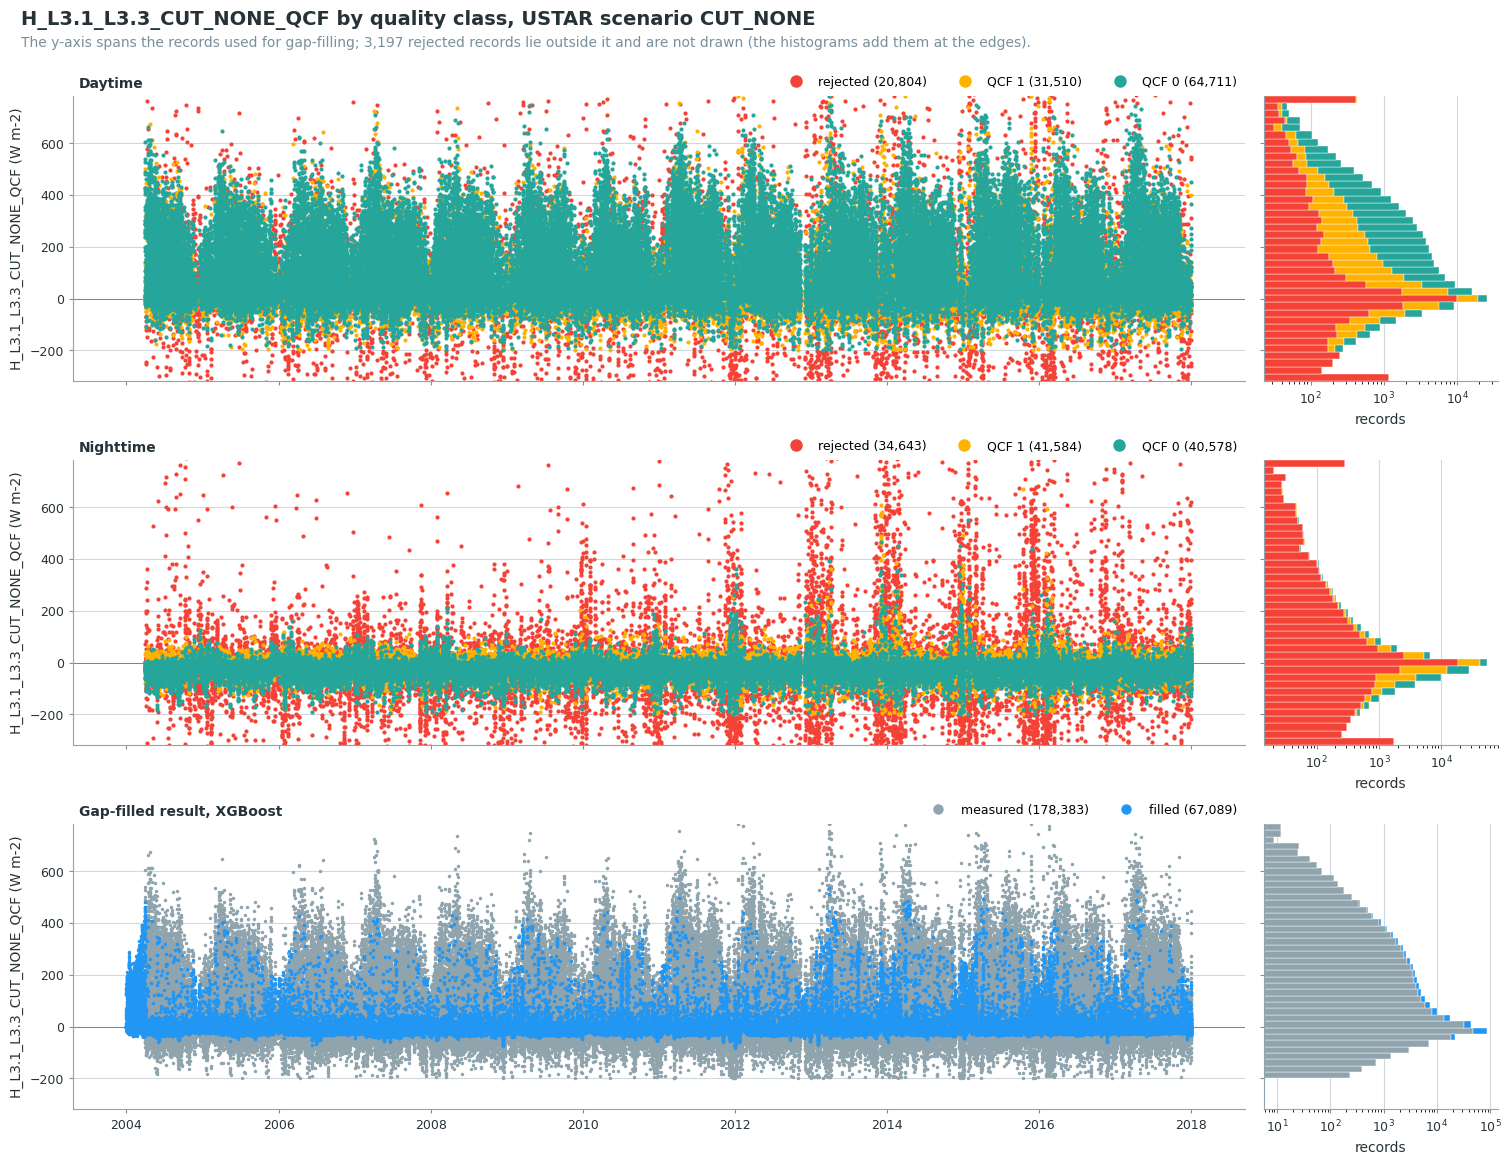

In [43]:
plot_quality_timeseries(data, ustar_scenario=SCENARIO, units=FLUX_UNITS, method='xgb')

### 📊 Plot: measured and gap-filled flux

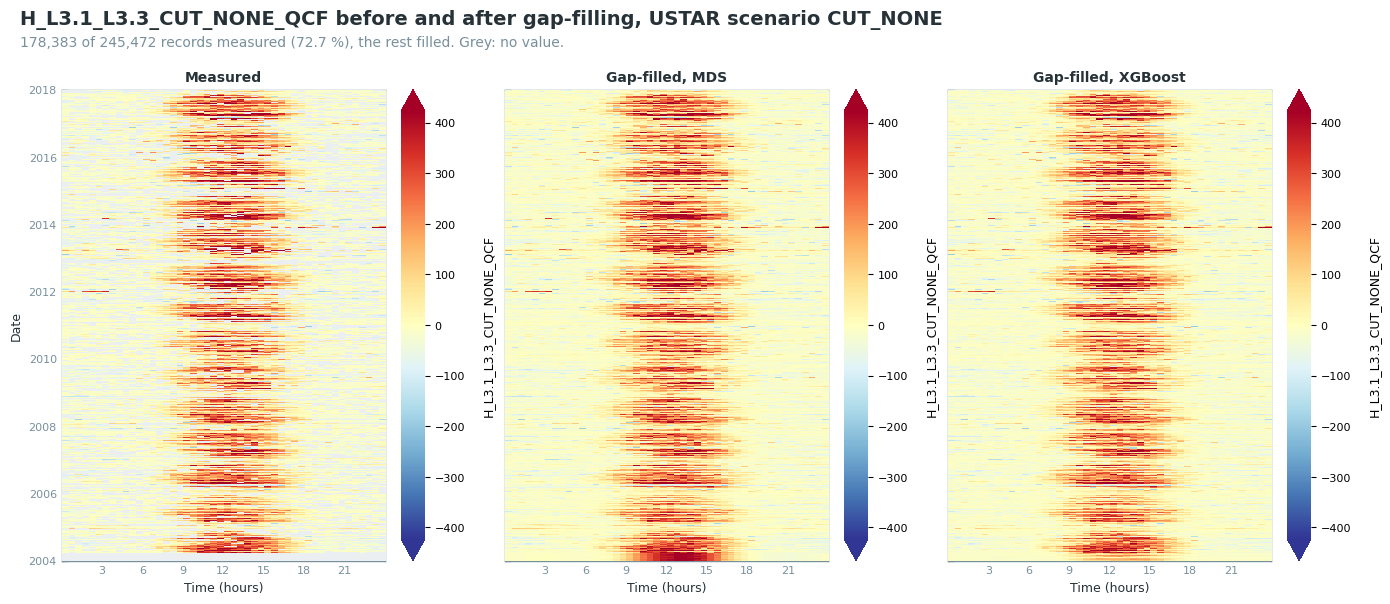

In [44]:
data.plot_gapfilled_heatmaps(ustar_scenario=SCENARIO)

### 📊 Plot: cumulative flux

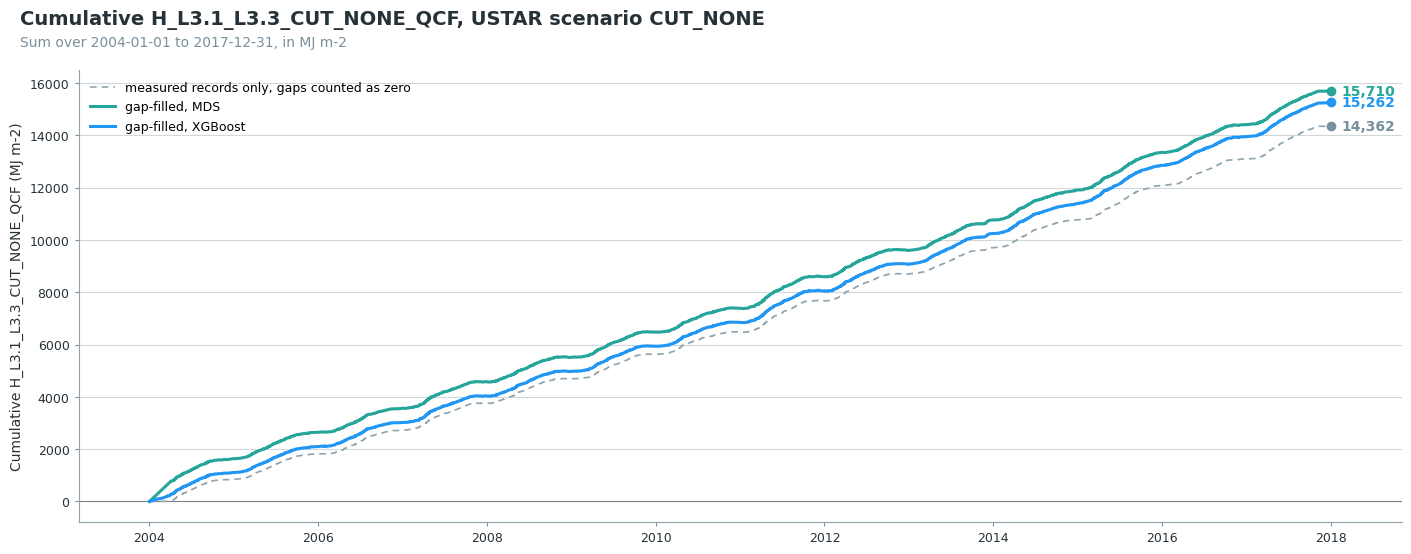

In [45]:
data.plot_cumulative_comparison(
    ustar_scenario=SCENARIO,
    conv_factor=WM2_TO_MJ,
    units='MJ m-2',
)

### 📊 Plot: cumulative flux of both gap-filling methods

One line per gap-filling method, each in its own colour, over the whole processed period.

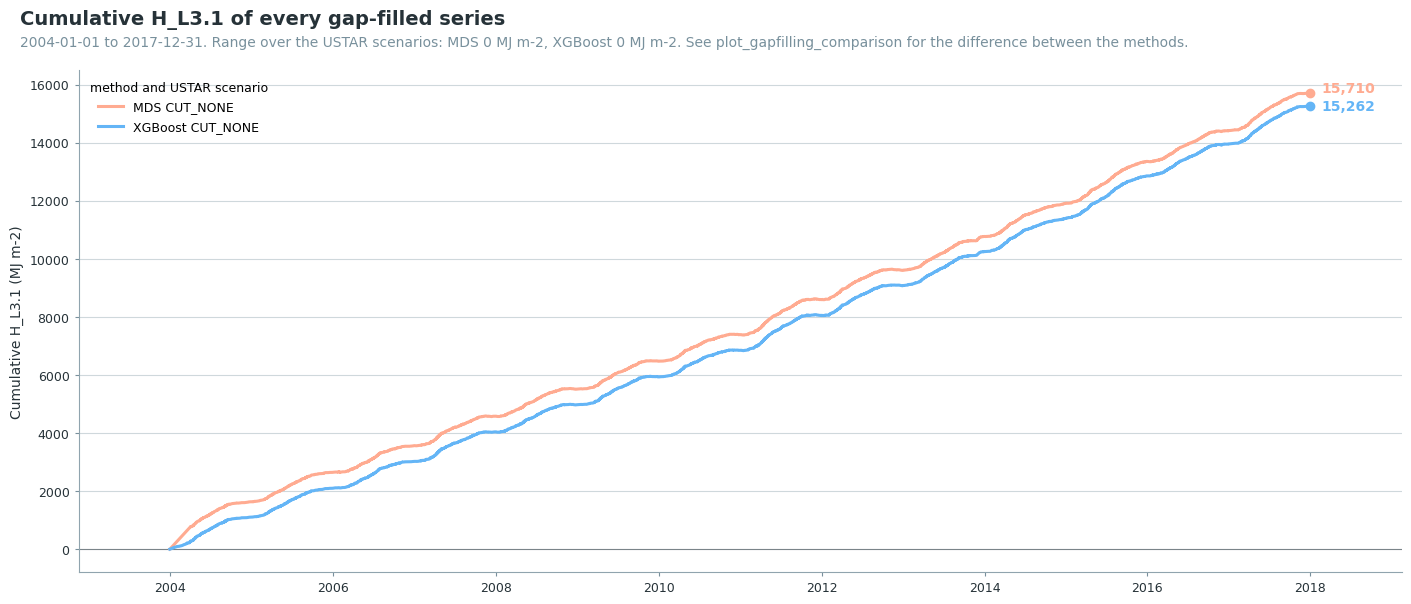

In [46]:
plot_gapfilled_cumulative(
    data,
    gain=WM2_TO_MJ,
    units='MJ m-2',
    per_year=False,
)

### 📊 Plot: cumulative flux per year

One panel per gap-filling method, on the same y-axis. One line per year; the band is the mean ± 1 SD
of the full years. An incomplete last year is left out of the band.

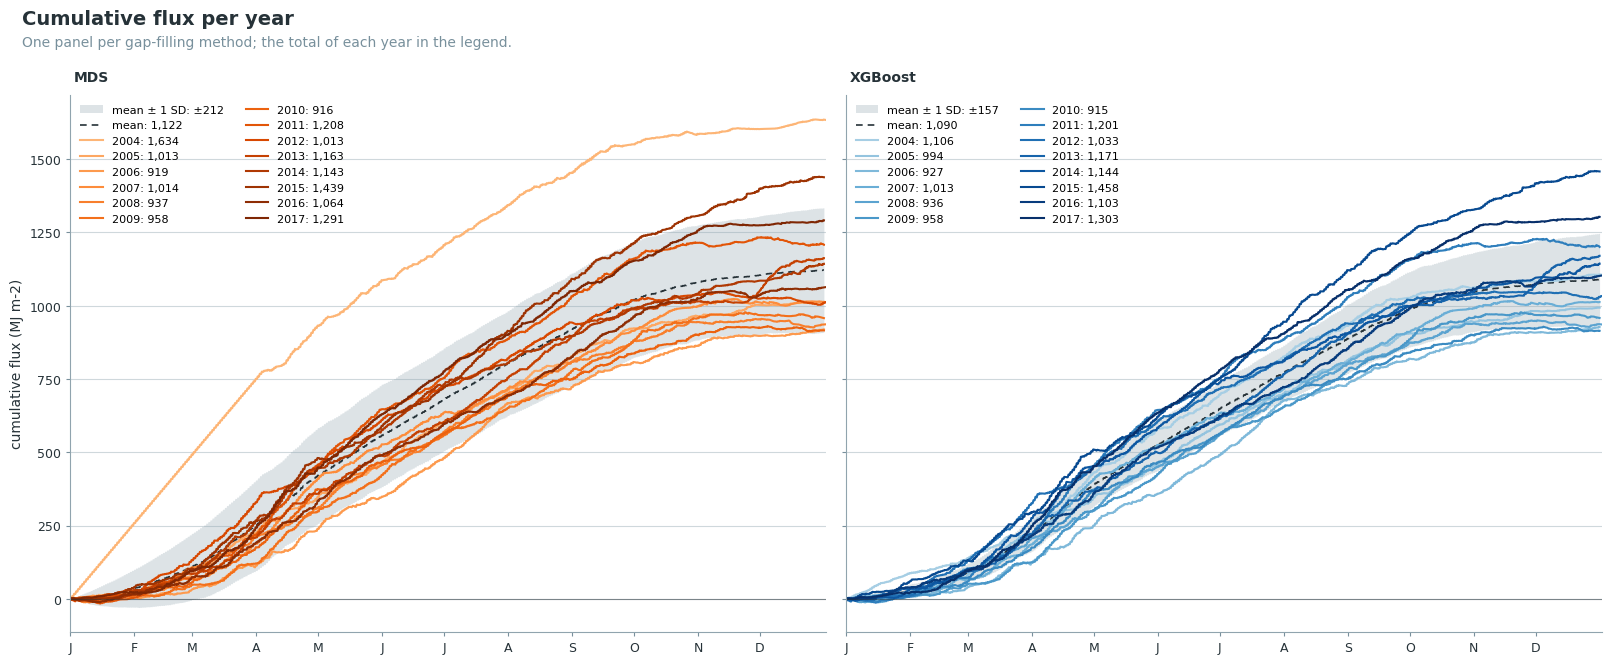

In [47]:
# One panel per gap-filling method, on a shared y-axis. Years run from light to dark, so the most
# recent year is the darkest line.
_gf = data.gapfilled_cols()
_names = {'mds': 'MDS', 'xgb': 'XGBoost', 'rf': 'random forest'}
_months = [1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335]
# A last year that ends before 31 December stays out of the mean and the band.
_end = data.fpc_df.index[-1]
_partial = [_end.year] if (_end.month, _end.day) != (12, 31) else None
fig, axes = plt.subplots(1, len(_gf), figsize=(8 * len(_gf), 6.6), sharex=True, sharey=True,
                         layout='constrained', squeeze=False)
for _ax, (_method, _cols) in zip(axes[0], _gf.items()):
    _cum = doy_cumulatives_per_year(data.fpc_df[_cols[SCENARIO]] * WM2_TO_MJ)
    _cum = _cum.loc[:, _cum.notna().any()]
    _years = list(_cum.columns)
    _shades = plt.get_cmap(cp.METHOD_CMAPS.get(_method, 'Greys'))(
        np.linspace(0.35, 1.0, len(_years)) if len(_years) > 1 else [0.85])
    if len(_years) > 1:
        _ref = doy_mean_cumulative(cumulatives_per_year_df=_cum,
                                   excl_years_from_reference=_partial)
        # Day 366 exists only in leap years, so the band stops before it.
        _ref = _ref.loc[_ref.index < 366]
        # The legend gives the mean and SD of the annual totals of the full years.
        _totals = [_cum[_y].dropna().iloc[-1] for _y in _years if _y not in (_partial or [])]
        _end_mean, _end_sd = np.mean(_totals), np.std(_totals, ddof=1)
        _ax.fill_between(_ref.index, _ref['MEAN-SD'], _ref['MEAN+SD'], color=cp.KEPT,
                         alpha=0.3, linewidth=0, label=f'mean ± 1 SD: ±{_end_sd:,.0f}')
        _ax.plot(_ref.index, _ref['MEAN_DOY_TIME'], color=cp.INK, linewidth=1.2,
                 linestyle=(0, (4, 3)), label=f'mean: {_end_mean:,.0f}')
    for _shade, _year in zip(_shades, _years):
        _valid = _cum[_year].dropna()
        _ax.plot(_cum.index, _cum[_year], color=_shade, linewidth=1.5,
                 label=f"{_year}: {_valid.iloc[-1]:,.0f}")
    _ax.axhline(0, color=cp.INK, linewidth=0.8, alpha=0.5)
    cp.style_axes(_ax)
    cp.panel_label(_ax, _names.get(_method, _method))
    _ax.set_xticks(_months, ['J', 'F', 'M', 'A', 'M', 'J', 'J', 'A', 'S', 'O', 'N', 'D'])
    _ax.set_xlim(1, 367)
    _ax.legend(frameon=False, fontsize=8, ncol=1 if len(_years) < 8 else 2)
axes[0][0].set_ylabel('cumulative flux (MJ m-2)')
_subtitle = "One panel per gap-filling method; the total of each year in the legend."
if _partial:
    _subtitle += f" {_end.year} ends on {_end:%d %B} and is left out of the mean and the band."
cp.figure_title(fig, 'Cumulative flux per year', _subtitle)
plt.show()

### Gap-filling methods compared

The difference between the sums of MDS and XGBoost comes from the filled gaps alone; the table
splits it by day and night and by gap length ([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#method-comparison)).

**Skipped** when `RUN_MDS = False`.

#### 📋 Table: MDS and XGBoost, sums and their difference

In [48]:
if RUN_MDS:
    report_gapfilling_comparison(data, methods=('mds', 'xgb'), gain=WM2_TO_MJ, units='MJ m-2');

Gap-filling methods compared: MDS and XGBoost
              sum       sum                    from         from   gaps   gaps    gaps   gaps
USTAR         MDS   XGBoost   difference   day gaps   night gaps      1   2-12   13-48    >48
─────────────────────────────────────────────────────────────────────────────────────────────
CUT_NONE   15,710    15,262         -448       -424          -23    -21    -13      25   -438
Sums (MJ m-2). difference = XGBoost - MDS over the filled gaps, split into daytime and nighttime 
gaps and by gap length in records.
CUT_NONE, same 44,448 held-out records: MDS R² 0.77 RMSE 55.43, XGBoost R² 0.80 RMSE 50.74
Held-out records are random single half-hours, so these scores describe short gaps; the sums depend 
more on the long ones.

#### 📊 Plot: where MDS and XGBoost differ

The filled values of both methods at the same gaps, their mean difference by month and hour, the
contribution of each month to the difference of the sums, and the cumulative difference.

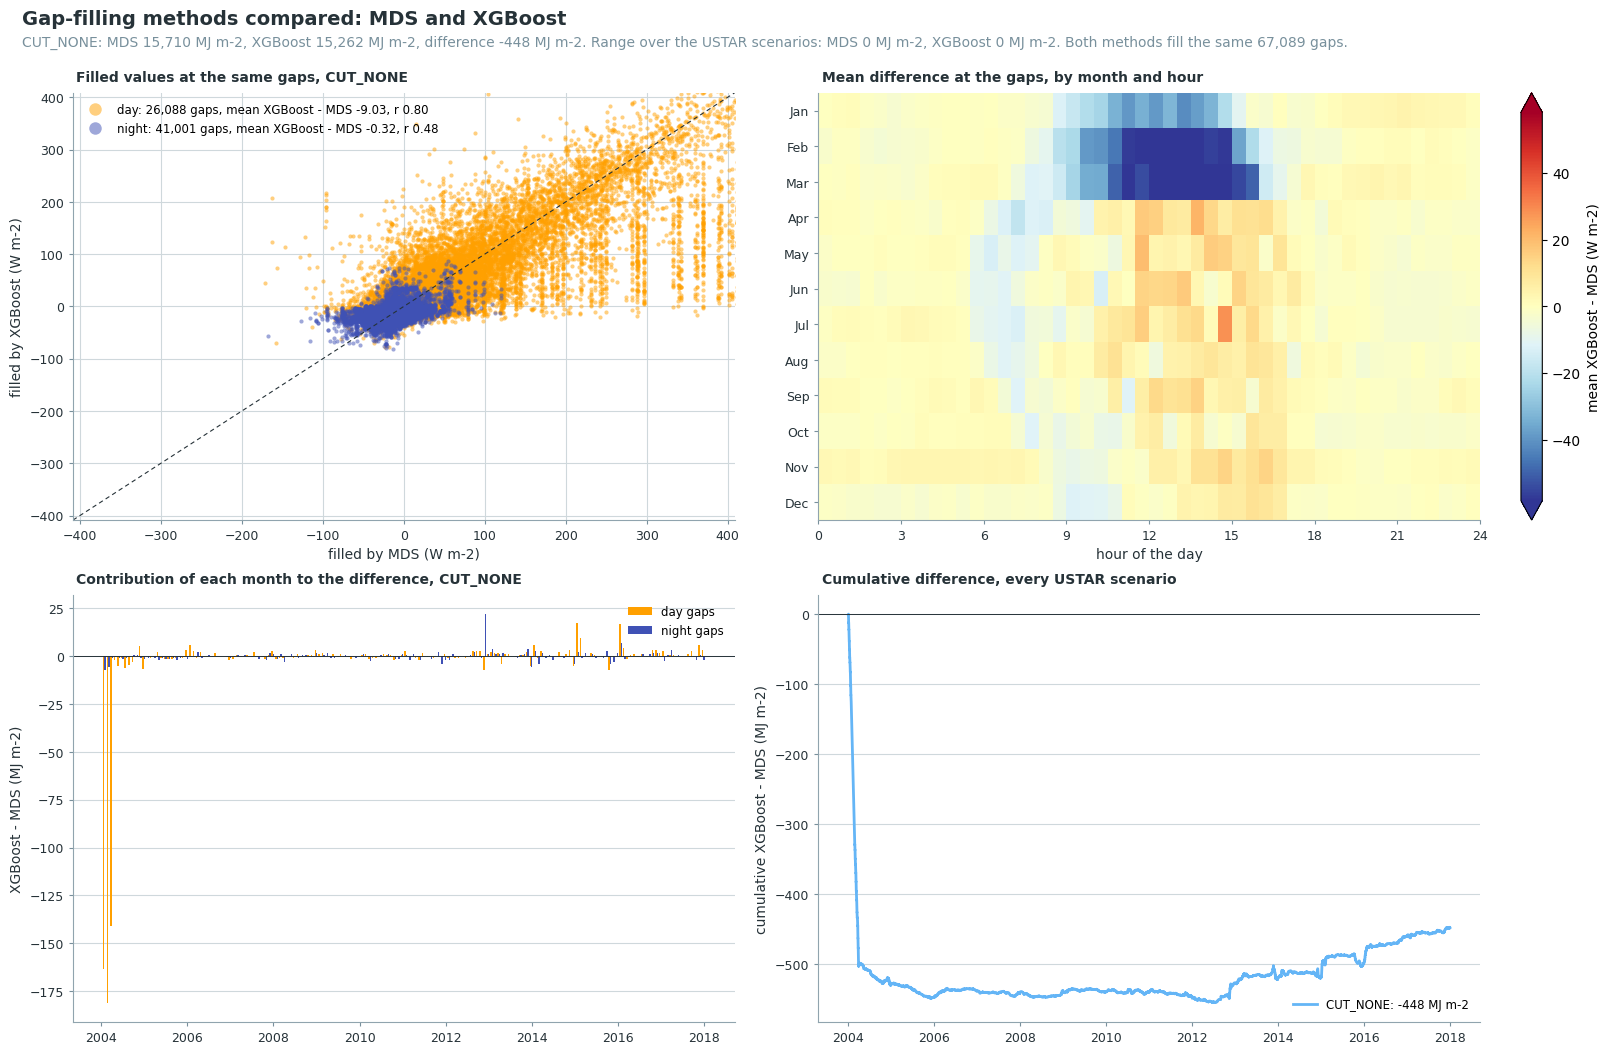

In [49]:
if RUN_MDS:
    plot_gapfilling_comparison(data, ustar_scenario=SCENARIO, methods=('mds', 'xgb'),
                               gain=WM2_TO_MJ, units='MJ m-2', flux_units=FLUX_UNITS);

## 💾 Step 11: export

The output file holds only the columns this notebook adds: the flags and series of every level and
the gap-filled flux. The input columns stay in the input file; the merge into the fullset joins the
flux outputs with it on the timestamp.

In [50]:
_all = data.merged_df()
out_df = _all[[c for c in _all.columns if c not in df.columns]]
assert out_df.index.equals(df.index), "the output timestamps differ from the input"
print(f"{out_df.shape[0]:,} records x {out_df.shape[1]} columns "
      f"(input columns left out: {_all.shape[1] - out_df.shape[1]})")
filepath = dv.save_parquet(data=out_df, filename=OUTNAME, outpath=OUTPATH)

> New variables from the flux post-processing chain: 40 (L2: 12, L3.1: 7, L3.2: 10, L3.3: 7, L4.1:
4)

> No variables in the input data were overwritten, only new variables added.

245,472 records x 43 columns (input columns left out: 348)


> Saved file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\30_FLUX_POST-PROC
ESSING_CHAIN\IRGA75\35_FPPC_IRGA75_H_2004-2017.parquet (0.857 seconds).

***

# End of notebook.

In [51]:
NOTEBOOK_END = datetime.now()
_h, _rem = divmod(int((NOTEBOOK_END - NOTEBOOK_START).total_seconds()), 3600)
_m, _s = divmod(_rem, 60)

print(f"Started:  {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Finished: {NOTEBOOK_END.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Runtime:  {_h:02d}:{_m:02d}:{_s:02d} (hh:mm:ss)")

Started:  2026-10-30 18:47:13
Finished: 2026-10-30 19:15:59
Runtime:  00:28:46 (hh:mm:ss)
